In [ ]:

# CELL 1: Upload the PSL ball-by-ball CSV

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

uploaded = files.upload()

# Find the uploaded CSV file
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload a CSV file.")

file_path = csv_files[0]

# Read the dataset
df_raw = pd.read_csv(file_path, low_memory=False)

# Preserve a working copy
df = df_raw.copy()

print("Dataset uploaded successfully!")
print("File:", file_path)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Saving psl_male_ball_by_ball.csv to psl_male_ball_by_ball (1).csv
Dataset uploaded successfully!
File: psl_male_ball_by_ball (1).csv
Rows: 83799
Columns: 64


In [ ]:

# CELL 2: Initial inspection

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nNumeric summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include="object").T)


Dataset shape: (83799, 64)

First five rows:


,match_id,date,match_type,event_name,innings,batting_team,bowling_team,over,ball,ball_no,...,team_balls,team_wicket,new_batter,power_surge_start,batter_runs,batter_balls,bowler_wicket,batting_partners,striker_out,next_batter
0,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,0,1,0.1,...,1,0,NaN,NaN,0,1,0,SR Watson|Sharjeel Khan,0,NaN
1,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,0,2,0.2,...,2,0,NaN,NaN,0,2,0,SR Watson|Sharjeel Khan,0,NaN
2,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,0,3,0.3,...,3,0,NaN,NaN,0,3,0,SR Watson|Sharjeel Khan,0,NaN
3,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,0,4,0.4,...,4,0,NaN,NaN,0,4,0,SR Watson|Sharjeel Khan,0,NaN
4,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,0,5,0.5,...,5,0,NaN,NaN,0,5,0,SR Watson|Sharjeel Khan,0,NaN



Last five rows:


,match_id,date,match_type,event_name,innings,batting_team,bowling_team,over,ball,ball_no,...,team_balls,team_wicket,new_batter,power_surge_start,batter_runs,batter_balls,bowler_wicket,batting_partners,striker_out,next_batter
83794,1527595,2026-05-03,T20,Pakistan Super League,2,Peshawar Zalmi,Hyderabad Kingsmen,14,4,14.4,...,88,4,NaN,NaN,48,33,0,AM Hardie|Abdul Samad,0,NaN
83795,1527595,2026-05-03,T20,Pakistan Super League,2,Peshawar Zalmi,Hyderabad Kingsmen,14,5,14.5,...,89,5,NaN,NaN,48,34,1,AM Hardie|Abdul Samad,1,Farhan Yousaf
83796,1527595,2026-05-03,T20,Pakistan Super League,2,Peshawar Zalmi,Hyderabad Kingsmen,14,6,14.6,...,90,5,Farhan Yousaf,NaN,0,1,0,AM Hardie|Farhan Yousaf,0,NaN
83797,1527595,2026-05-03,T20,Pakistan Super League,2,Peshawar Zalmi,Hyderabad Kingsmen,15,1,15.1,...,91,5,NaN,NaN,56,39,0,AM Hardie|Farhan Yousaf,0,NaN
83798,1527595,2026-05-03,T20,Pakistan Super League,2,Peshawar Zalmi,Hyderabad Kingsmen,15,2,15.2,...,92,5,NaN,NaN,4,2,0,AM Hardie|Farhan Yousaf,0,NaN



Column names:
['match_id', 'date', 'match_type', 'event_name', 'innings', 'batting_team', 'bowling_team', 'over', 'ball', 'ball_no', 'batter', 'bat_pos', 'runs_batter', 'balls_faced', 'bowler', 'valid_ball', 'runs_extras', 'runs_total', 'runs_bowler', 'runs_not_boundary', 'extra_type', 'non_striker', 'non_striker_pos', 'wicket_kind', 'player_out', 'fielders', 'runs_target', 'review_batter', 'team_reviewed', 'review_decision', 'umpire', 'umpires_call', 'player_of_match', 'match_won_by', 'win_outcome', 'toss_winner', 'toss_decision', 'venue', 'city', 'day', 'month', 'year', 'season', 'gender', 'team_type', 'superover_winner', 'result_type', 'method', 'balls_per_over', 'overs', 'event_match_no', 'stage', 'match_number', 'team_runs', 'team_balls', 'team_wicket', 'new_batter', 'power_surge_start', 'batter_runs', 'batter_balls', 'bowler_wicket', 'batting_partners', 'striker_out', 'next_batter']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83799 entries,

,count,mean,std,min,25%,50%,75%,max
match_id,83799.0,1.281271e+06,162035.313684,959175.0,1168830.0,1293000.0,1416492.0,1527595.0
innings,83799.0,1.480781e+00,0.501921,1.0,1.0,1.0,2.0,4.0
over,83799.0,9.102221e+00,5.638768,0.0,4.0,9.0,14.0,19.0
ball,83799.0,3.485853e+00,1.708741,1.0,2.0,3.0,5.0,7.0
ball_no,83799.0,9.450806e+00,5.640129,0.1,4.5,9.4,14.3,19.6
bat_pos,83799.0,3.737002e+00,2.259514,1.0,2.0,3.0,5.0,11.0
runs_batter,83799.0,1.302128e+00,1.673571,0.0,0.0,1.0,1.0,6.0
balls_faced,83799.0,9.685915e-01,0.174420,0.0,1.0,1.0,1.0,1.0
valid_ball,83799.0,9.644029e-01,0.185284,0.0,1.0,1.0,1.0,1.0
runs_extras,83799.0,7.046623e-02,0.360343,0.0,0.0,0.0,0.0,5.0



Categorical summary:


,count,unique,top,freq
date,83799,275,2024-02-18,509
match_type,83799,1,T20,83799
event_name,83799,1,Pakistan Super League,83799
batting_team,83799,8,Peshawar Zalmi,14658
bowling_team,83799,8,Islamabad United,14637
batter,83799,420,Babar Azam,3472
bowler,83799,300,Hasan Ali,2357
extra_type,4572,7,wides,2632
non_striker,83799,414,Babar Azam,3678
wicket_kind,4506,10,caught,2760


In [ ]:

# CELL 3: Generate a data dictionary template

data_dictionary = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "non_null_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "unique_values": df.nunique(dropna=True).values
})

display(data_dictionary)

data_dictionary.to_csv("psl_data_dictionary.csv", index=False)
print("Saved: psl_data_dictionary.csv")


,column,data_type,non_null_count,missing_count,unique_values
0,match_id,int64,83799,0,357
1,date,object,83799,0,275
2,match_type,object,83799,0,1
3,event_name,object,83799,0,1
4,innings,int64,83799,0,4
...,...,...,...,...,...
59,batter_balls,int64,83799,0,68
60,bowler_wicket,int64,83799,0,2
61,batting_partners,object,83799,0,2285
62,striker_out,int64,83799,0,2


Saved: psl_data_dictionary.csv


,missing_count,missing_percentage,data_type
power_surge_start,83799,100.00,float64
umpire,83206,99.29,object
review_decision,83159,99.24,object
team_reviewed,83159,99.24,object
review_batter,83159,99.24,object
...,...,...,...
batter_runs,0,0.00,int64
batter_balls,0,0.00,int64
bowler_wicket,0,0.00,int64
batting_partners,0,0.00,object


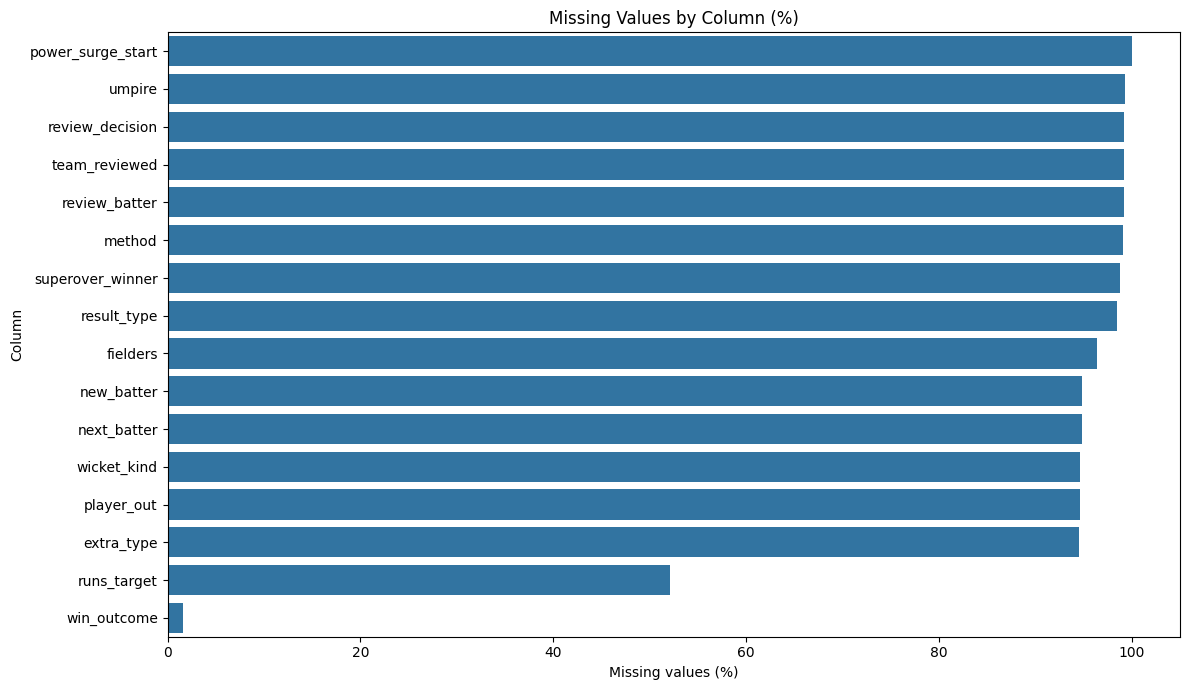

In [ ]:

# CELL 4: Missing-value analysis

missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "data_type": df.dtypes.astype(str)
}).sort_values("missing_percentage", ascending=False)

display(missing_report)

plt.figure(figsize=(12, 7))
missing_plot = missing_report[missing_report["missing_count"] > 0]

sns.barplot(
    x=missing_plot["missing_percentage"],
    y=missing_plot.index
)

plt.title("Missing Values by Column (%)")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

missing_report.to_csv("psl_missing_values_report.csv")


In [ ]:

# CELL 5: Duplicate analysis

exact_duplicate_count = int(df.duplicated().sum())

print("Total rows:", len(df))
print("Exact duplicate rows:", exact_duplicate_count)
print(
    "Duplicate percentage:",
    round(exact_duplicate_count / len(df) * 100, 3), "%"
)

# Inspect the duplicates before deciding what to do
duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows.head(20))

# Check possible repeated delivery identifiers separately
delivery_key = ["match_id", "innings", "over", "ball"]

if all(col in df.columns for col in delivery_key):
    repeated_delivery_keys = df[
        df.duplicated(subset=delivery_key, keep=False)
    ].sort_values(delivery_key)

    print(
        "\nRows sharing a match/innings/over/ball key:",
        len(repeated_delivery_keys)
    )
    display(repeated_delivery_keys.head(20))

duplicate_report = pd.DataFrame({
    "metric": [
        "Total rows",
        "Exact duplicate rows",
        "Rows with repeated delivery keys"
    ],
    "value": [
        len(df),
        exact_duplicate_count,
        len(repeated_delivery_keys)
        if all(col in df.columns for col in delivery_key)
        else np.nan
    ]
})

display(duplicate_report)
duplicate_report.to_csv("psl_duplicate_report.csv", index=False)


Total rows: 83799
Exact duplicate rows: 0
Duplicate percentage: 0.0 %


,match_id,date,match_type,event_name,innings,batting_team,bowling_team,over,ball,ball_no,...,team_balls,team_wicket,new_batter,power_surge_start,batter_runs,batter_balls,bowler_wicket,batting_partners,striker_out,next_batter



Rows sharing a match/innings/over/ball key: 5796


,match_id,date,match_type,event_name,innings,batting_team,bowling_team,over,ball,ball_no,...,team_balls,team_wicket,new_batter,power_surge_start,batter_runs,batter_balls,bowler_wicket,batting_partners,striker_out,next_batter
37,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,6,2,6.2,...,37,1,NaN,NaN,0,3,0,SR Watson|Umar Amin,0,NaN
38,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,6,2,6.2,...,38,2,NaN,NaN,0,4,1,SR Watson|Umar Amin,1,Babar Azam
94,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,15,4,15.4,...,93,6,NaN,NaN,6,4,0,AD Russell|Misbah-ul-Haq,0,NaN
95,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,15,4,15.4,...,94,6,NaN,NaN,6,5,0,AD Russell|Misbah-ul-Haq,0,NaN
113,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,18,4,18.4,...,111,6,NaN,NaN,37,26,0,AD Russell|Misbah-ul-Haq,0,NaN
114,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,18,4,18.4,...,112,6,NaN,NaN,41,27,0,AD Russell|Misbah-ul-Haq,0,NaN
115,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,18,5,18.5,...,112,6,NaN,NaN,41,27,0,AD Russell|Misbah-ul-Haq,0,NaN
116,959175,2016-02-04,T20,Pakistan Super League,1,Islamabad United,Quetta Gladiators,18,5,18.5,...,113,7,NaN,NaN,41,28,1,AD Russell|Misbah-ul-Haq,1,S Badree
156,959175,2016-02-04,T20,Pakistan Super League,2,Quetta Gladiators,Islamabad United,5,3,5.3,...,32,1,NaN,NaN,42,20,0,KP Pietersen|LJ Wright,0,NaN
157,959175,2016-02-04,T20,Pakistan Super League,2,Quetta Gladiators,Islamabad United,5,3,5.3,...,33,1,NaN,NaN,42,21,0,KP Pietersen|LJ Wright,0,NaN


,metric,value
0,Total rows,83799
1,Exact duplicate rows,0
2,Rows with repeated delivery keys,5796


In [ ]:

# CELL 6: Data consistency checks

# Parse dates without deleting records
parsed_dates = pd.to_datetime(df["date"], errors="coerce")

# Check whether numeric fields are stored as expected
numeric_candidates = [
    "innings", "over", "ball", "runs_batter",
    "runs_extras", "runs_total", "valid_ball"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

checks = {}

checks["invalid_dates"] = int(parsed_dates.isna().sum())

checks["missing_match_id"] = int(df["match_id"].isna().sum())
checks["missing_batting_team"] = int(df["batting_team"].isna().sum())
checks["missing_bowling_team"] = int(df["bowling_team"].isna().sum())

checks["negative_batter_runs"] = int(
    (df["runs_batter"] < 0).sum()
)

checks["negative_total_runs"] = int(
    (df["runs_total"] < 0).sum()
)

checks["innings_not_positive_integer"] = int(
    (
        df["innings"].notna()
        & (
            (df["innings"] < 1)
            | (df["innings"] % 1 != 0)
        )
    ).sum()
)

checks["batting_team_equals_bowling_team"] = int(
    (
        df["batting_team"].notna()
        & df["bowling_team"].notna()
        & (df["batting_team"] == df["bowling_team"])
    ).sum()
)

# In ordinary delivery accounting, total runs should equal batter runs + extras.
# Flag discrepancies for inspection; do not automatically overwrite source values.
run_components_available = df[
    ["runs_batter", "runs_extras", "runs_total"]
].notna().all(axis=1)

run_mismatch = (
    df.loc[run_components_available, "runs_total"]
    != (
        df.loc[run_components_available, "runs_batter"]
        + df.loc[run_components_available, "runs_extras"]
    )
)

checks["run_total_component_mismatches"] = int(run_mismatch.sum())

consistency_report = pd.DataFrame(
    list(checks.items()),
    columns=["check", "count"]
)

display(consistency_report)
consistency_report.to_csv("psl_consistency_report.csv", index=False)

# Show the rows requiring closer inspection
if run_mismatch.any():
    mismatch_indices = run_mismatch[run_mismatch].index
    display(
        df.loc[
            mismatch_indices,
            ["match_id", "innings", "over", "ball",
             "runs_batter", "runs_extras", "runs_total"]
        ].head(20)
    )


,check,count
0,invalid_dates,0
1,missing_match_id,0
2,missing_batting_team,0
3,missing_bowling_team,0
4,negative_batter_runs,0
5,negative_total_runs,0
6,innings_not_positive_integer,0
7,batting_team_equals_bowling_team,0
8,run_total_component_mismatches,0


,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,runs_batter,0.0,1.0,1.0,-1.5,2.5,14745,17.596
1,runs_extras,0.0,0.0,0.0,0.0,0.0,4572,5.456
2,runs_total,0.0,1.0,1.0,-1.5,2.5,15103,18.023


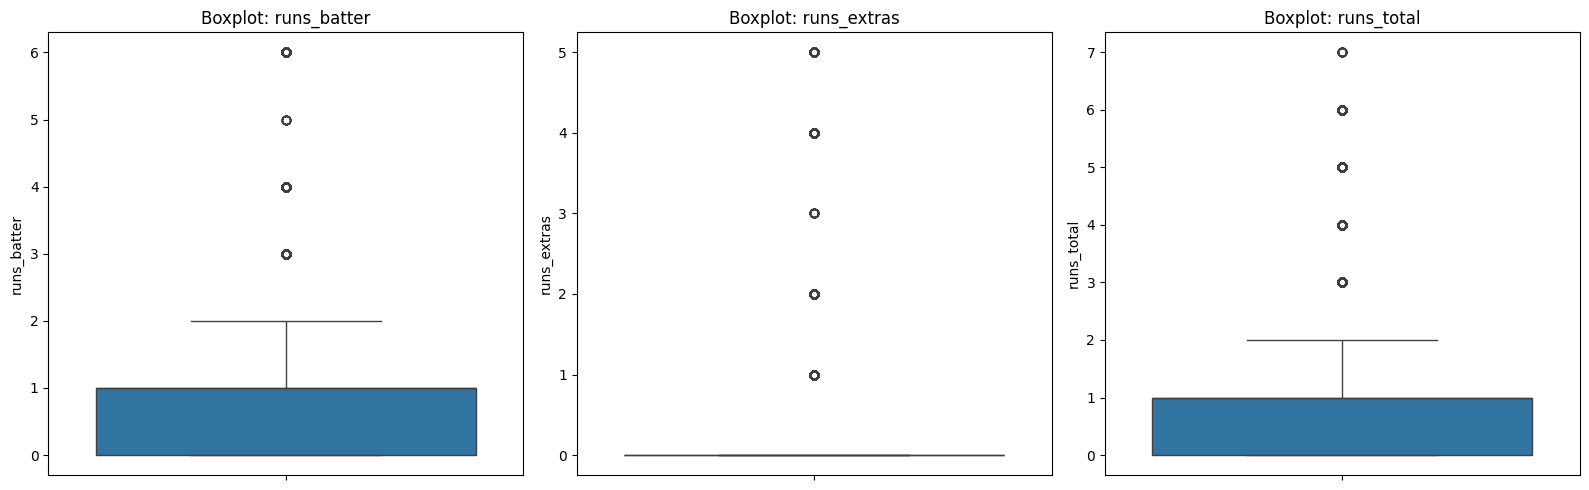

In [ ]:

# CELL 7: Outlier detection using IQR

outlier_columns = ["runs_batter", "runs_extras", "runs_total"]

outlier_results = []

for col in outlier_columns:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (values < lower_bound) | (values > upper_bound)

    outlier_results.append({
        "column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percentage": round(outlier_mask.mean() * 100, 3)
    })

outlier_report = pd.DataFrame(outlier_results)
display(outlier_report)

outlier_report.to_csv("psl_outlier_report.csv", index=False)

# Visualize the distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, outlier_columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot: {col}")

plt.tight_layout()
plt.show()


In [ ]:

# CELL 8: Conservative cleaning

df_clean = df.copy()

# Remove exact duplicate rows only
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
exact_duplicates_removed = rows_before - len(df_clean)

# Standardize surrounding whitespace in text fields
text_columns = df_clean.select_dtypes(include=["object"]).columns

for col in text_columns:
    df_clean[col] = df_clean[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Parse dates; invalid values become missing and are reported
df_clean["date"] = pd.to_datetime(
    df_clean["date"], errors="coerce"
)

print("Rows before cleaning:", rows_before)
print("Exact duplicates removed:", exact_duplicates_removed)
print("Rows after cleaning:", len(df_clean))
print("Columns after cleaning:", len(df_clean.columns))
print("Missing dates after parsing:", df_clean["date"].isna().sum())

# Save cleaned data
df_clean.to_csv("psl_cleaned_ball_by_ball.csv", index=False)

print("Saved: psl_cleaned_ball_by_ball.csv")


Rows before cleaning: 83799
Exact duplicates removed: 0
Rows after cleaning: 83799
Columns after cleaning: 64
Missing dates after parsing: 0
Saved: psl_cleaned_ball_by_ball.csv


Total ball-level rows: 83799
Unique matches: 357
Unique batting teams: 8
Unique bowling teams: 8
Unique batters: 420
Unique bowlers: 300
Unique venues: 10

Date range:
Start: 2016-02-04 00:00:00
End: 2026-05-03 00:00:00

Matches per season:


,matches
season,
2015/16,23
2016/17,24
2017/18,33
2018/19,34
2019/20,28
2020/21,18
2021,20
2021/22,34
2022/23,34


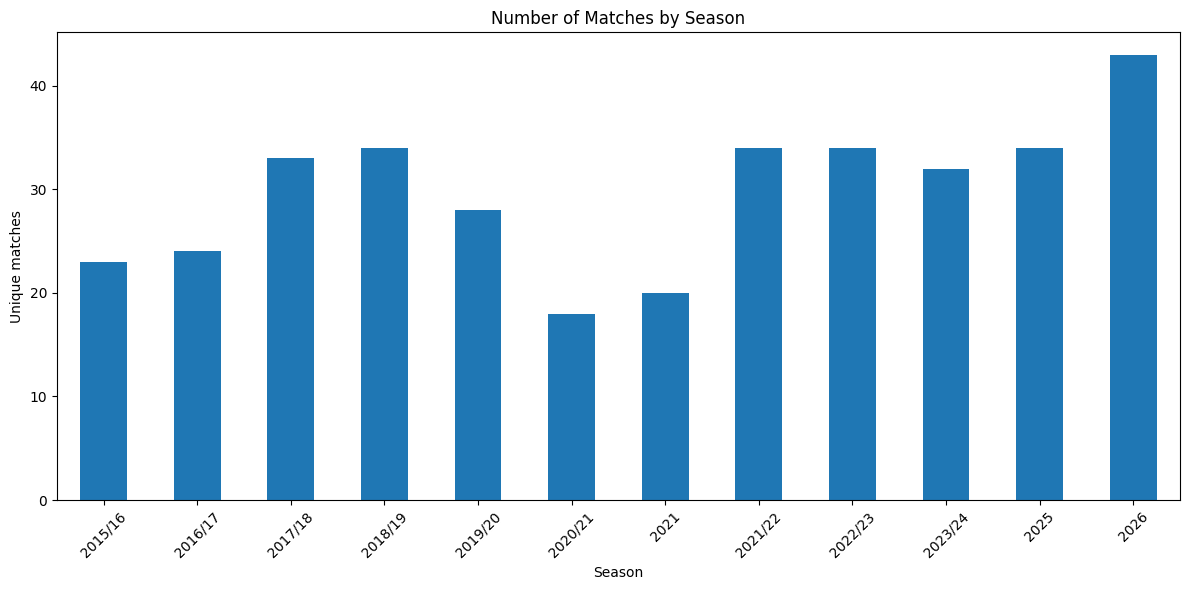

In [ ]:

# CELL 9: Basic dataset statistics

print("Total ball-level rows:", len(df_clean))
print("Unique matches:", df_clean["match_id"].nunique())
print("Unique batting teams:", df_clean["batting_team"].nunique())
print("Unique bowling teams:", df_clean["bowling_team"].nunique())
print("Unique batters:", df_clean["batter"].nunique())
print("Unique bowlers:", df_clean["bowler"].nunique())
print("Unique venues:", df_clean["venue"].nunique())

print("\nDate range:")
print("Start:", df_clean["date"].min())
print("End:", df_clean["date"].max())

print("\nMatches per season:")
season_matches = (
    df_clean.drop_duplicates("match_id")
    .groupby("season")["match_id"]
    .nunique()
    .sort_index()
)

display(season_matches.to_frame("matches"))

plt.figure(figsize=(12, 6))
season_matches.plot(kind="bar")
plt.title("Number of Matches by Season")
plt.xlabel("Season")
plt.ylabel("Unique matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


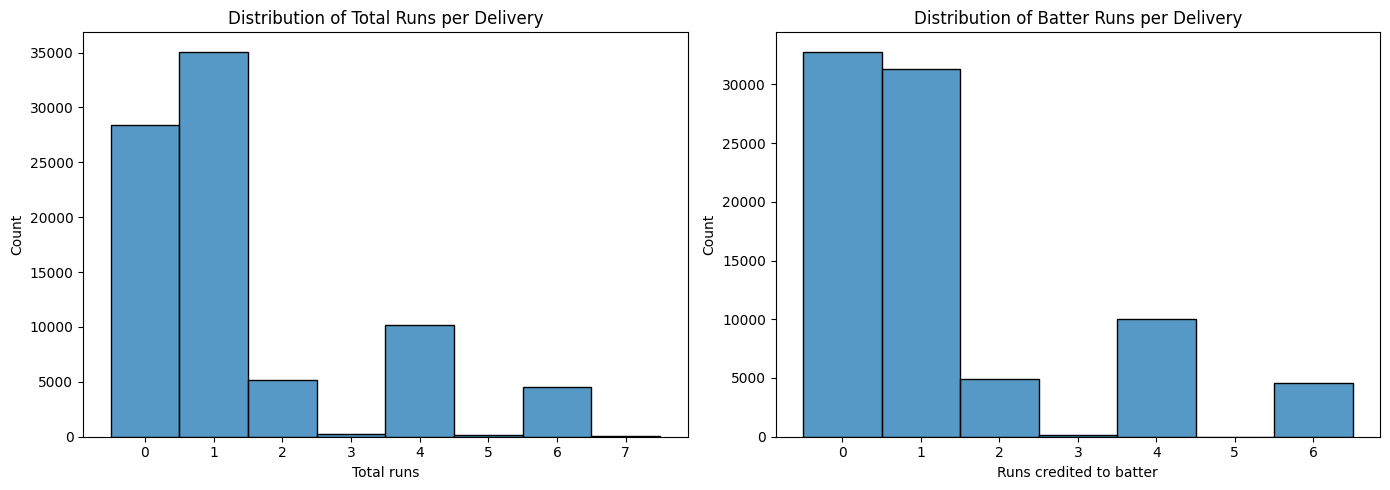


Total runs by delivery outcome:


,delivery_count
runs_total,
0,28391
1,35093
2,5212
3,210
4,10167
5,179
6,4517
7,30



Dismissal types:


,count
wicket_kind,
caught,2760
bowled,847
run out,341
lbw,334
caught and bowled,122
stumped,89
hit wicket,8
retired hurt,3
obstructing the field,1


In [ ]:

# CELL 10: Distribution of delivery-level runs

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df_clean, x="runs_total",
    discrete=True, ax=axes[0]
)
axes[0].set_title("Distribution of Total Runs per Delivery")
axes[0].set_xlabel("Total runs")

sns.histplot(
    data=df_clean, x="runs_batter",
    discrete=True, ax=axes[1]
)
axes[1].set_title("Distribution of Batter Runs per Delivery")
axes[1].set_xlabel("Runs credited to batter")

plt.tight_layout()
plt.show()

print("\nTotal runs by delivery outcome:")
display(df_clean["runs_total"].value_counts().sort_index().to_frame("delivery_count"))

print("\nDismissal types:")
display(
    df_clean["wicket_kind"]
    .value_counts(dropna=True)
    .to_frame("count")
)


In [ ]:

# CELL 11: Aggregate deliveries into innings

required_cols = [
    "match_id", "innings", "batting_team", "bowling_team",
    "runs_total", "valid_ball", "wicket_kind"
]

missing_required = [
    col for col in required_cols if col not in df_clean.columns
]

if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

innings_stats = (
    df_clean.groupby(
        ["match_id", "innings", "batting_team", "bowling_team"],
        dropna=False
    )
    .agg(
        total_runs=("runs_total", "sum"),
        legal_balls=("valid_ball", "sum"),
        wickets=("wicket_kind", lambda s: s.notna().sum())
    )
    .reset_index()
)

innings_stats["run_rate"] = np.where(
    innings_stats["legal_balls"] > 0,
    innings_stats["total_runs"] * 6 / innings_stats["legal_balls"],
    np.nan
)

print("Number of innings records:", len(innings_stats))
display(innings_stats.head(10))

print("\nSummary of innings statistics:")
display(
    innings_stats[
        ["total_runs", "legal_balls", "wickets", "run_rate"]
    ].describe().T
)

innings_stats.to_csv("psl_innings_statistics.csv", index=False)


Number of innings records: 719


,match_id,innings,batting_team,bowling_team,total_runs,legal_balls,wickets,run_rate
0,959175,1,Islamabad United,Quetta Gladiators,128,120,7,6.400000
1,959175,2,Quetta Gladiators,Islamabad United,132,96,2,8.250000
2,959177,1,Lahore Qalandars,Karachi Kings,125,120,8,6.250000
3,959177,2,Karachi Kings,Lahore Qalandars,131,95,3,8.273684
4,959179,1,Peshawar Zalmi,Islamabad United,145,120,7,7.250000
5,959179,2,Islamabad United,Peshawar Zalmi,121,120,9,6.050000
6,959181,1,Karachi Kings,Quetta Gladiators,147,120,7,7.350000
7,959181,2,Quetta Gladiators,Karachi Kings,153,104,2,8.826923
8,959183,1,Lahore Qalandars,Peshawar Zalmi,117,120,6,5.850000
9,959183,2,Peshawar Zalmi,Lahore Qalandars,118,96,1,7.375000



Summary of innings statistics:


,count,mean,std,min,25%,50%,75%,max
total_runs,719.0,159.974965,37.489266,5.000000,137.0,161.000000,185.000000,263.0
legal_balls,719.0,112.400556,16.714739,2.000000,112.0,120.000000,120.000000,121.0
wickets,719.0,6.267038,2.587932,0.000000,4.0,6.000000,8.000000,10.0
run_rate,719.0,8.602736,1.780798,3.529412,7.4,8.461538,9.663842,24.0


,phase,runs,legal_balls,wickets,deliveries,run_rate,wickets_per_100_legal_balls
0,Death,29487,17421,1609,18357,10.155674,9.235980
1,Middle,50359,37754,1805,38823,8.003231,4.780950
2,Powerplay,35176,25641,1092,26619,8.231192,4.258804


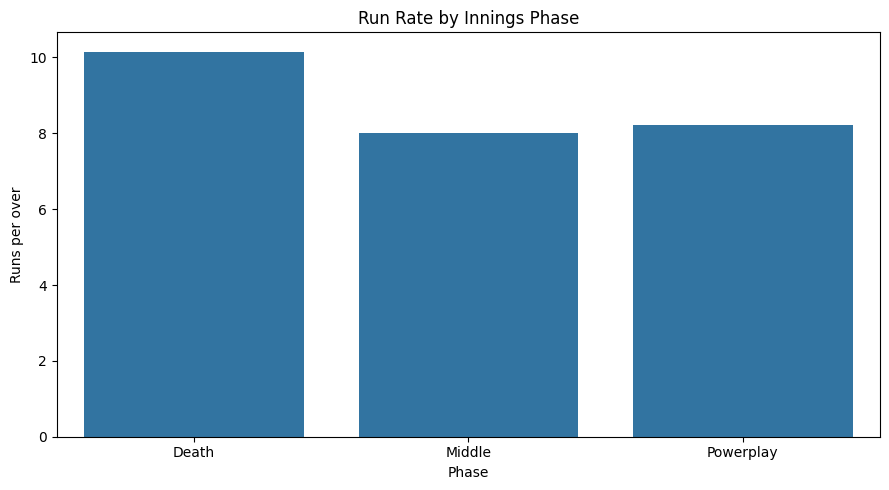

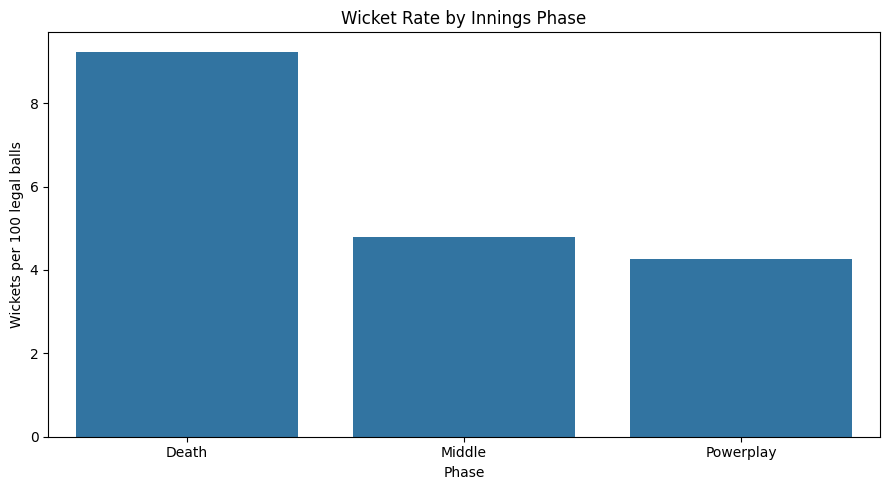

In [ ]:

# CELL 12: Phase-wise run rate and wicket rate

phase_df = df_clean.copy()

phase_df["over"] = pd.to_numeric(
    phase_df["over"], errors="coerce"
)

phase_df["phase"] = np.select(
    [
        phase_df["over"].between(0, 5),
        phase_df["over"].between(6, 14),
        phase_df["over"].between(15, 19)
    ],
    [
        "Powerplay",
        "Middle",
        "Death"
    ],
    default="Other / inspect"
)

phase_summary = (
    phase_df.groupby("phase", dropna=False)
    .agg(
        runs=("runs_total", "sum"),
        legal_balls=("valid_ball", "sum"),
        wickets=("wicket_kind", lambda s: s.notna().sum()),
        deliveries=("match_id", "size")
    )
    .reset_index()
)

phase_summary["run_rate"] = np.where(
    phase_summary["legal_balls"] > 0,
    phase_summary["runs"] * 6 / phase_summary["legal_balls"],
    np.nan
)

phase_summary["wickets_per_100_legal_balls"] = np.where(
    phase_summary["legal_balls"] > 0,
    phase_summary["wickets"] * 100 / phase_summary["legal_balls"],
    np.nan
)

display(phase_summary)

plot_data = phase_summary[
    phase_summary["phase"].isin(["Powerplay", "Middle", "Death"])
]

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_data, x="phase", y="run_rate")
plt.title("Run Rate by Innings Phase")
plt.xlabel("Phase")
plt.ylabel("Runs per over")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=plot_data,
    x="phase",
    y="wickets_per_100_legal_balls"
)
plt.title("Wicket Rate by Innings Phase")
plt.xlabel("Phase")
plt.ylabel("Wickets per 100 legal balls")
plt.tight_layout()
plt.show()


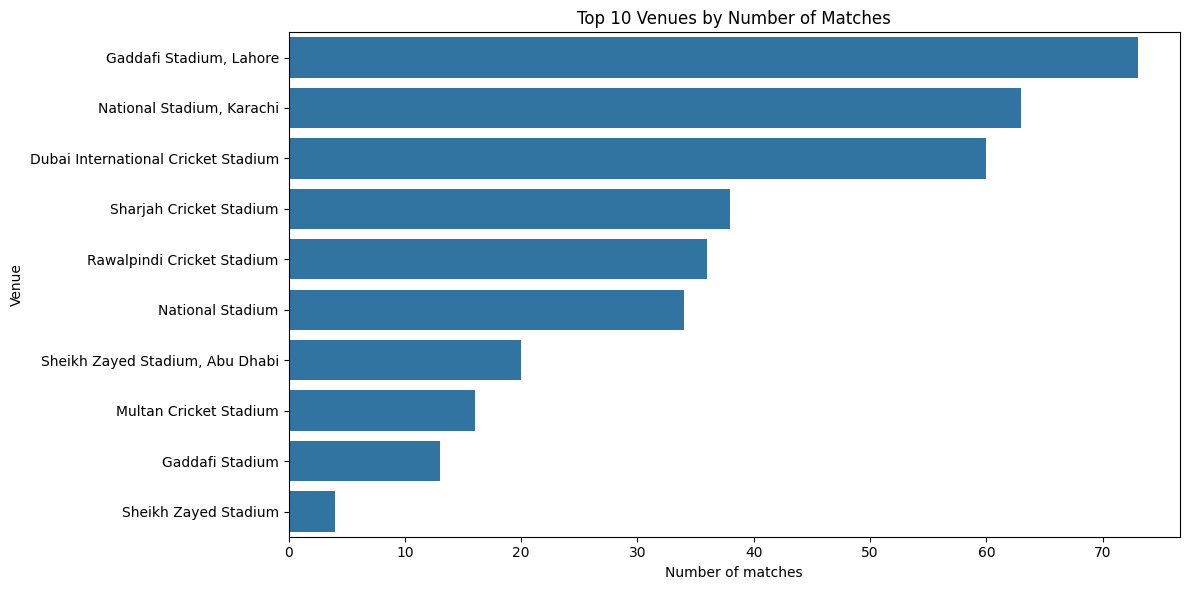

,season,average_innings_runs,average_run_rate,innings_count
0,2015/16,144.217391,7.620401,46
1,2016/17,145.042553,7.737981,47
2,2017/18,139.457143,8.110144,70
3,2018/19,153.779412,8.016871,68
4,2019/20,157.200000,8.835018,55
5,2020/21,157.105263,8.776141,38
6,2021,160.900000,8.573250,40
7,2021/22,164.714286,8.802777,70
8,2022/23,177.220588,9.155488,68
9,2023/24,170.453125,8.720836,64


In [ ]:

# CELL 13: Venue and season analysis

match_level = (
    df_clean.sort_values("date")
    .groupby("match_id", as_index=False)
    .agg(
        date=("date", "first"),
        season=("season", "first"),
        venue=("venue", "first"),
        match_won_by=("match_won_by", "first"),
        toss_winner=("toss_winner", "first"),
        toss_decision=("toss_decision", "first"),
        result_type=("result_type", "first")
    )
)

venue_counts = (
    match_level["venue"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=venue_counts.values, y=venue_counts.index)
plt.title("Top 10 Venues by Number of Matches")
plt.xlabel("Number of matches")
plt.ylabel("Venue")
plt.tight_layout()
plt.show()

# Average runs per innings by season
season_runs = (
    innings_stats.merge(
        match_level[["match_id", "season"]],
        on="match_id",
        how="left"
    )
    .groupby("season", dropna=False)
    .agg(
        average_innings_runs=("total_runs", "mean"),
        average_run_rate=("run_rate", "mean"),
        innings_count=("total_runs", "size")
    )
    .reset_index()
)

display(season_runs.sort_values("season"))
season_runs.to_csv("psl_season_eda.csv", index=False)


In [ ]:

# CELL 14: Toss-win hypothesis test

from scipy.stats import binomtest

toss_data = match_level.dropna(
    subset=["toss_winner", "match_won_by"]
).copy()

# Exclude ties between teams in the toss/result comparison if any
toss_data = toss_data[
    toss_data["toss_winner"] != ""
].copy()

toss_data["toss_winner_won_match"] = (
    toss_data["toss_winner"] == toss_data["match_won_by"]
)

n_matches = len(toss_data)
toss_winner_match_wins = int(
    toss_data["toss_winner_won_match"].sum()
)

if n_matches == 0:
    print("No eligible matches for the toss hypothesis test.")
else:
    observed_rate = toss_winner_match_wins / n_matches

    test_result = binomtest(
        k=toss_winner_match_wins,
        n=n_matches,
        p=0.5,
        alternative="two-sided"
    )

    print("Eligible matches:", n_matches)
    print("Toss-winning team also won:", toss_winner_match_wins)
    print("Observed proportion:", round(observed_rate, 4))
    print("Observed percentage:", round(observed_rate * 100, 2), "%")
    print("Null proportion: 50%")
    print("Exact binomial p-value:", test_result.pvalue)
    print("95% confidence interval:", test_result.proportion_ci())

    alpha = 0.05

    if test_result.pvalue < alpha:
        print(
            "\nDecision: Reject H0 at the 5% significance level. "
            "The observed proportion differs statistically from 50%."
        )
    else:
        print(
            "\nDecision: Fail to reject H0 at the 5% significance level. "
            "There is insufficient evidence that the proportion differs "
            "from 50%."
        )


Eligible matches: 357
Toss-winning team also won: 205
Observed proportion: 0.5742
Observed percentage: 57.42 %
Null proportion: 50%
Exact binomial p-value: 0.005844383228390558
95% confidence interval: ConfidenceInterval(low=0.5210997386682535, high=0.6261181741189474)

Decision: Reject H0 at the 5% significance level. The observed proportion differs statistically from 50%.


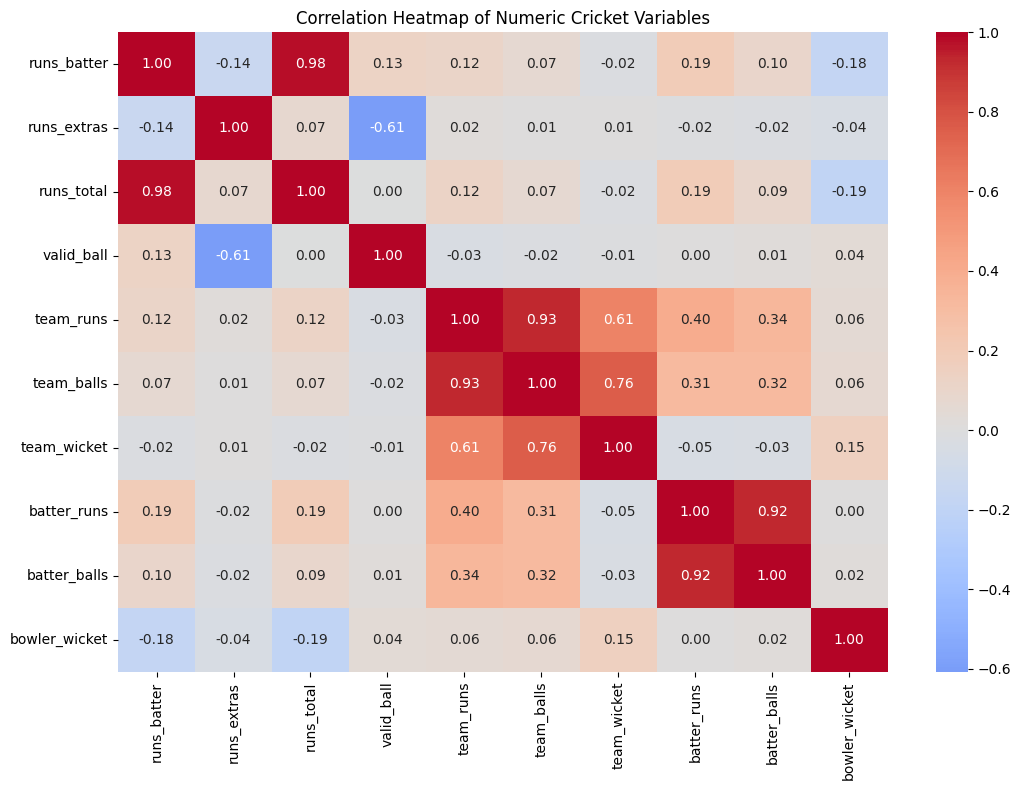

,runs_batter,runs_extras,runs_total,valid_ball,team_runs,team_balls,team_wicket,batter_runs,batter_balls,bowler_wicket
runs_batter,1.000000,-0.142516,0.976673,0.131703,0.119103,0.066193,-0.022258,0.193257,0.097117,-0.177717
runs_extras,-0.142516,1.000000,0.073350,-0.608024,0.017520,0.006849,0.005033,-0.017538,-0.019418,-0.043480
runs_total,0.976673,0.073350,1.000000,0.000793,0.123809,0.068181,-0.021335,0.190920,0.093642,-0.188499
valid_ball,0.131703,-0.608024,0.000793,1.000000,-0.032438,-0.019090,-0.013418,0.003044,0.014025,0.041543
team_runs,0.119103,0.017520,0.123809,-0.032438,1.000000,0.931652,0.609171,0.402025,0.338513,0.055446
team_balls,0.066193,0.006849,0.068181,-0.019090,0.931652,1.000000,0.756296,0.310801,0.318914,0.064373
team_wicket,-0.022258,0.005033,-0.021335,-0.013418,0.609171,0.756296,1.000000,-0.048065,-0.031809,0.152813
batter_runs,0.193257,-0.017538,0.190920,0.003044,0.402025,0.310801,-0.048065,1.000000,0.924713,0.002164
batter_balls,0.097117,-0.019418,0.093642,0.014025,0.338513,0.318914,-0.031809,0.924713,1.000000,0.016454
bowler_wicket,-0.177717,-0.043480,-0.188499,0.041543,0.055446,0.064373,0.152813,0.002164,0.016454,1.000000


In [ ]:

# CELL 15: Correlation heatmap

correlation_columns = [
    "runs_batter",
    "runs_extras",
    "runs_total",
    "valid_ball",
    "team_runs",
    "team_balls",
    "team_wicket",
    "batter_runs",
    "batter_balls",
    "bowler_wicket"
]

correlation_columns = [
    col for col in correlation_columns
    if col in df_clean.columns
]

correlation_data = df_clean[correlation_columns].apply(
    pd.to_numeric, errors="coerce"
)

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Numeric Cricket Variables")
plt.tight_layout()
plt.show()

display(correlation_matrix)
correlation_matrix.to_csv("psl_correlation_matrix.csv")


In [ ]:

# CELL 16: Final quality summary

final_quality_summary = pd.DataFrame({
    "metric": [
        "Original rows",
        "Original columns",
        "Unique matches before cleaning",
        "Exact duplicate rows removed",
        "Cleaned rows",
        "Cleaned columns",
        "Unique matches after cleaning",
        "Missing cells after cleaning",
        "Invalid dates after parsing"
    ],
    "value": [
        len(df_raw),
        len(df_raw.columns),
        df_raw["match_id"].nunique(),
        exact_duplicates_removed,
        len(df_clean),
        len(df_clean.columns),
        df_clean["match_id"].nunique(),
        int(df_clean.isna().sum().sum()),
        int(df_clean["date"].isna().sum())
    ]
})

display(final_quality_summary)

final_quality_summary.to_csv(
    "psl_final_quality_summary.csv",
    index=False
)

print("All main M1 analysis steps completed.")


,metric,value
0,Original rows,83799
1,Original columns,64
2,Unique matches before cleaning,357
3,Exact duplicate rows removed,0
4,Cleaned rows,83799
5,Cleaned columns,64
6,Unique matches after cleaning,357
7,Missing cells after cleaning,1187261
8,Invalid dates after parsing,0


All main M1 analysis steps completed.


In [ ]:

# CELL 17: Package the M1 outputs

import zipfile

output_files = [
    "psl_data_dictionary.csv",
    "psl_missing_values_report.csv",
    "psl_duplicate_report.csv",
    "psl_consistency_report.csv",
    "psl_outlier_report.csv",
    "psl_cleaned_ball_by_ball.csv",
    "psl_innings_statistics.csv",
    "psl_season_eda.csv",
    "psl_correlation_matrix.csv",
    "psl_final_quality_summary.csv"
]

with zipfile.ZipFile(
    "PSL_M1_Data_Quality_and_EDA.zip", "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:
    for filename in output_files:
        if os.path.exists(filename):
            zipf.write(filename)

print("Created PSL_M1_Data_Quality_and_EDA.zip")

files.download("PSL_M1_Data_Quality_and_EDA.zip")


Created PSL_M1_Data_Quality_and_EDA.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# CELL 18: Delivery-Level Feature Engineering

# Create a separate feature engineering dataset
delivery_features = df_clean.copy()

# Ensure numeric columns have correct data types
numeric_cols = [
    "over", "ball", "runs_total", "runs_batter",
    "team_runs", "team_balls", "team_wicket",
    "balls_per_over", "overs", "batter_runs", "batter_balls"
]

for col in numeric_cols:
    delivery_features[col] = pd.to_numeric(
        delivery_features[col], errors="coerce"
    )

# 1. Current Run Rate
delivery_features["current_run_rate"] = np.where(
    delivery_features["team_balls"] > 0,
    (delivery_features["team_runs"] * 6) /
    delivery_features["team_balls"],
    0
)

# 2. Wickets Remaining
delivery_features["wickets_remaining"] = (
    10 - delivery_features["team_wicket"]
)

# 3. Overs Remaining
delivery_features["scheduled_balls"] = (
    delivery_features["overs"] *
    delivery_features["balls_per_over"]
)

delivery_features["balls_remaining"] = (
    delivery_features["scheduled_balls"] -
    delivery_features["team_balls"]
).clip(lower=0)

delivery_features["overs_remaining"] = (
    delivery_features["balls_remaining"] /
    delivery_features["balls_per_over"]
)

# 4. Innings Phase
delivery_features["innings_phase"] = np.select(
    [
        delivery_features["over"].between(0, 5),
        delivery_features["over"].between(6, 14),
        delivery_features["over"].between(15, 19)
    ],
    ["Powerplay", "Middle", "Death"],
    default="Other"
)

# 5. Boundary indicators
delivery_features["is_four"] = (
    delivery_features["runs_batter"] == 4
).astype(int)

delivery_features["is_six"] = (
    delivery_features["runs_batter"] == 6
).astype(int)

# 6. Extra runs indicator
delivery_features["has_extras"] = (
    delivery_features["runs_extras"] > 0
).astype(int)

# 7. Wicket indicator
delivery_features["is_wicket"] = (
    delivery_features["wicket_kind"].notna()
).astype(int)

# 8. Batter Strike Rate
delivery_features["batter_strike_rate"] = np.where(
    delivery_features["batter_balls"] > 0,
    (delivery_features["batter_runs"] * 100) /
    delivery_features["batter_balls"],
    0
)

# Display selected engineered features
new_features = [
    "match_id",
    "innings",
    "batting_team",
    "over",
    "team_runs",
    "team_balls",
    "current_run_rate",
    "wickets_remaining",
    "overs_remaining",
    "innings_phase",
    "is_four",
    "is_six",
    "is_wicket",
    "batter_strike_rate"
]

display(delivery_features[new_features].head(15))

print("Original dataset shape:", df_clean.shape)
print("Feature-engineered dataset shape:", delivery_features.shape)

print("\nNew features created:")
print([
    "current_run_rate",
    "wickets_remaining",
    "scheduled_balls",
    "balls_remaining",
    "overs_remaining",
    "innings_phase",
    "is_four",
    "is_six",
    "has_extras",
    "is_wicket",
    "batter_strike_rate"
])


,match_id,innings,batting_team,over,team_runs,team_balls,current_run_rate,wickets_remaining,overs_remaining,innings_phase,is_four,is_six,is_wicket,batter_strike_rate
0,959175,1,Islamabad United,0,0,1,0.000000,10,19.833333,Powerplay,0,0,0,0.000000
1,959175,1,Islamabad United,0,0,2,0.000000,10,19.666667,Powerplay,0,0,0,0.000000
2,959175,1,Islamabad United,0,0,3,0.000000,10,19.500000,Powerplay,0,0,0,0.000000
3,959175,1,Islamabad United,0,0,4,0.000000,10,19.333333,Powerplay,0,0,0,0.000000
4,959175,1,Islamabad United,0,0,5,0.000000,10,19.166667,Powerplay,0,0,0,0.000000
5,959175,1,Islamabad United,0,0,6,0.000000,10,19.000000,Powerplay,0,0,0,0.000000
6,959175,1,Islamabad United,1,0,7,0.000000,10,18.833333,Powerplay,0,0,0,0.000000
7,959175,1,Islamabad United,1,1,8,0.750000,10,18.666667,Powerplay,0,0,0,50.000000
8,959175,1,Islamabad United,1,3,9,2.000000,10,18.500000,Powerplay,0,0,0,28.571429
9,959175,1,Islamabad United,1,3,10,1.800000,10,18.333333,Powerplay,0,0,0,25.000000


Original dataset shape: (83799, 64)
Feature-engineered dataset shape: (83799, 75)

New features created:
['current_run_rate', 'wickets_remaining', 'scheduled_balls', 'balls_remaining', 'overs_remaining', 'innings_phase', 'is_four', 'is_six', 'has_extras', 'is_wicket', 'batter_strike_rate']


In [ ]:

# CELL 19: Innings-Level Feature Engineering

# Work from the cleaned ball-by-ball dataset
innings_features = df_clean.copy()

# Create batting phase
innings_features["phase"] = np.select(
    [
        innings_features["over"].between(0, 5),
        innings_features["over"].between(6, 14),
        innings_features["over"].between(15, 19)
    ],
    ["powerplay", "middle", "death"],
    default="other"
)

# Create boundary and dot-ball indicators
innings_features["four"] = (
    innings_features["runs_batter"] == 4
).astype(int)

innings_features["six"] = (
    innings_features["runs_batter"] == 6
).astype(int)

innings_features["dot_ball"] = (
    (innings_features["valid_ball"] == 1) &
    (innings_features["runs_total"] == 0)
).astype(int)

# Create boundary runs
innings_features["boundary_runs"] = (
    innings_features["four"] * 4 +
    innings_features["six"] * 6
)

# Group deliveries into innings
group_cols = [
    "match_id",
    "innings",
    "batting_team",
    "bowling_team",
    "season",
    "venue"
]

# Calculate basic innings statistics
innings_summary = (
    innings_features
    .groupby(group_cols)
    .agg(
        total_runs=("runs_total", "sum"),
        legal_balls=("valid_ball", "sum"),
        wickets_lost=("wicket_kind", "count"),
        fours=("four", "sum"),
        sixes=("six", "sum"),
        dot_balls=("dot_ball", "sum"),
        boundary_runs=("boundary_runs", "sum"),
        extras=("runs_extras", "sum")
    )
    .reset_index()
)

# Calculate run rate
innings_summary["run_rate"] = np.where(
    innings_summary["legal_balls"] > 0,
    innings_summary["total_runs"] * 6 /
    innings_summary["legal_balls"],
    0
)

# Calculate batting phase runs
phase_runs = (
    innings_features
    .groupby(group_cols + ["phase"])["runs_total"]
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

# Rename phase columns
phase_runs = phase_runs.rename(columns={
    "powerplay": "powerplay_runs",
    "middle": "middle_overs_runs",
    "death": "death_overs_runs"
})

# Merge phase statistics into innings summary
innings_summary = innings_summary.merge(
    phase_runs,
    on=group_cols,
    how="left"
)

# Display results
print("Innings-level dataset created successfully!")
print("Shape:", innings_summary.shape)

display(innings_summary.head(10))

# Statistical summary
print("\nInnings feature statistics:")
display(
    innings_summary[
        [
            "total_runs",
            "legal_balls",
            "wickets_lost",
            "run_rate",
            "fours",
            "sixes",
            "dot_balls"
        ]
    ].describe().round(2)
)


Innings-level dataset created successfully!
Shape: (719, 18)


,match_id,innings,batting_team,bowling_team,season,venue,total_runs,legal_balls,wickets_lost,fours,sixes,dot_balls,boundary_runs,extras,run_rate,death_overs_runs,middle_overs_runs,powerplay_runs
0,959175,1,Islamabad United,Quetta Gladiators,2015/16,Dubai International Cricket Stadium,128,120,7,10,4,59,64,4,6.400000,64,42,22
1,959175,2,Quetta Gladiators,Islamabad United,2015/16,Dubai International Cricket Stadium,132,96,2,14,4,37,80,5,8.250000,13,61,58
2,959177,1,Lahore Qalandars,Karachi Kings,2015/16,Dubai International Cricket Stadium,125,120,8,9,2,46,48,9,6.250000,36,51,38
3,959177,2,Karachi Kings,Lahore Qalandars,2015/16,Dubai International Cricket Stadium,131,95,3,11,7,44,86,3,8.273684,13,61,57
4,959179,1,Peshawar Zalmi,Islamabad United,2015/16,Dubai International Cricket Stadium,145,120,7,10,3,44,58,17,7.250000,49,62,34
5,959179,2,Islamabad United,Peshawar Zalmi,2015/16,Dubai International Cricket Stadium,121,120,9,10,2,58,52,11,6.050000,31,49,41
6,959181,1,Karachi Kings,Quetta Gladiators,2015/16,Dubai International Cricket Stadium,147,120,7,9,3,39,54,11,7.350000,52,65,30
7,959181,2,Quetta Gladiators,Karachi Kings,2015/16,Dubai International Cricket Stadium,153,104,2,10,8,32,88,4,8.826923,24,90,39
8,959183,1,Lahore Qalandars,Peshawar Zalmi,2015/16,Dubai International Cricket Stadium,117,120,6,11,1,55,50,6,5.850000,50,40,27
9,959183,2,Peshawar Zalmi,Lahore Qalandars,2015/16,Dubai International Cricket Stadium,118,96,1,10,3,39,58,10,7.375000,7,68,43



Innings feature statistics:


,total_runs,legal_balls,wickets_lost,run_rate,fours,sixes,dot_balls
count,719.00,719.00,719.00,719.00,719.00,719.00,719.00
mean,159.97,112.40,6.27,8.60,13.93,6.32,39.49
std,37.49,16.71,2.59,1.78,4.75,3.40,10.12
min,5.00,2.00,0.00,3.53,0.00,0.00,0.00
25%,137.00,112.00,4.00,7.40,11.00,4.00,34.00
50%,161.00,120.00,6.00,8.46,14.00,6.00,39.00
75%,185.00,120.00,8.00,9.66,17.00,8.00,46.00
max,263.00,121.00,10.00,24.00,30.00,18.00,76.00


In [ ]:

# CELL 20: Validate Innings Features

print("Total innings:", len(innings_summary))

print("\nMissing values:")
display(innings_summary.isnull().sum())

print("\nCheck innings scores:")
print(
    innings_summary[
        ["total_runs", "legal_balls", "wickets_lost", "run_rate"]
    ].describe()
)

print("\nCheck phase runs against total runs:")

innings_summary["phase_runs_total"] = (
    innings_summary["powerplay_runs"].fillna(0) +
    innings_summary["middle_overs_runs"].fillna(0) +
    innings_summary["death_overs_runs"].fillna(0)
)

display(
    innings_summary[
        ["total_runs", "phase_runs_total"]
    ].head(10)
)


Total innings: 719

Missing values:


,0
match_id,0
innings,0
batting_team,0
bowling_team,0
season,0
venue,0
total_runs,0
legal_balls,0
wickets_lost,0
fours,0



Check innings scores:
       total_runs  legal_balls  wickets_lost    run_rate
count  719.000000   719.000000    719.000000  719.000000
mean   159.974965   112.400556      6.267038    8.602736
std     37.489266    16.714739      2.587932    1.780798
min      5.000000     2.000000      0.000000    3.529412
25%    137.000000   112.000000      4.000000    7.400000
50%    161.000000   120.000000      6.000000    8.461538
75%    185.000000   120.000000      8.000000    9.663842
max    263.000000   121.000000     10.000000   24.000000

Check phase runs against total runs:


,total_runs,phase_runs_total
0,128,128
1,132,132
2,125,125
3,131,131
4,145,145
5,121,121
6,147,147
7,153,153
8,117,117
9,118,118


In [ ]:

# CELL 21: Investigate Innings Anomalies

# 1. Number of unique matches
print("Unique matches:", innings_summary["match_id"].nunique())
print("Total innings:", len(innings_summary))

# 2. How many innings does each match contain?
innings_per_match = innings_summary.groupby("match_id").size()

print("\nInnings per match:")
display(innings_per_match.value_counts().sort_index())

# 3. Find matches with more than two innings
print("\nMatches with more than two innings:")
display(
    innings_per_match[innings_per_match > 2]
)

# 4. Find innings with more than 120 legal balls
print("\nInnings with more than 120 legal balls:")
display(
    innings_summary[innings_summary["legal_balls"] > 120]
)

# 5. Check innings with unusual scores or very few balls
print("\nInnings with fewer than 60 legal balls:")
display(
    innings_summary[innings_summary["legal_balls"] < 60][
        ["match_id", "innings", "batting_team",
         "total_runs", "legal_balls", "wickets_lost"]
    ].head(20)
)

# 6. Check phase totals across ALL innings
phase_columns = [
    "powerplay_runs",
    "middle_overs_runs",
    "death_overs_runs"
]

innings_summary["phase_runs_total"] = (
    innings_summary[phase_columns].fillna(0).sum(axis=1)
)

print("\nPhase reconciliation:")
print(
    "Mismatched innings:",
    (innings_summary["total_runs"] !=
     innings_summary["phase_runs_total"]).sum()
)


Unique matches: 357
Total innings: 719

Innings per match:


,count
1,3
2,350
4,4



Matches with more than two innings:


,0
match_id,
1128829,4
1128841,4
1211672,4
1293029,4



Innings with more than 120 legal balls:


,match_id,innings,batting_team,bowling_team,season,venue,total_runs,legal_balls,wickets_lost,fours,sixes,dot_balls,boundary_runs,extras,run_rate,death_overs_runs,middle_overs_runs,powerplay_runs,phase_runs_total
163,1168820,1,Lahore Qalandars,Islamabad United,2018/19,Dubai International Cricket Stadium,171,121,8,14,6,38,92,9,8.479339,36,78,57,171
558,1416502,1,Peshawar Zalmi,Multan Sultans,2023/24,"National Stadium, Karachi",146,121,7,15,1,42,66,9,7.239669,38,57,51,146



Innings with fewer than 60 legal balls:


,match_id,innings,batting_team,total_runs,legal_balls,wickets_lost
64,1075995,2,Karachi Kings,75,58,4
115,1128829,3,Lahore Qalandars,15,6,1
116,1128829,4,Islamabad United,19,6,0
141,1128841,3,Lahore Qalandars,11,6,2
142,1128841,4,Karachi Kings,8,6,1
267,1211661,2,Peshawar Zalmi,85,54,2
270,1211663,1,Islamabad United,91,54,7
271,1211663,2,Multan Sultans,94,40,1
288,1211672,3,Karachi Kings,13,6,2
289,1211672,4,Multan Sultans,9,6,0



Phase reconciliation:
Mismatched innings: 0


In [ ]:

# CELL 22: Match-Level Feature Engineering

# Separate first and second innings
first_innings = innings_summary[
    innings_summary["innings"] == 1
].copy()

second_innings = innings_summary[
    innings_summary["innings"] == 2
].copy()

# Select useful first-innings features
first_features = first_innings[
    [
        "match_id",
        "batting_team",
        "bowling_team",
        "season",
        "venue",
        "total_runs",
        "legal_balls",
        "wickets_lost",
        "run_rate",
        "fours",
        "sixes",
        "dot_balls",
        "powerplay_runs",
        "middle_overs_runs",
        "death_overs_runs"
    ]
].copy()

# Rename columns to identify first innings
first_features = first_features.rename(columns={
    "batting_team": "first_innings_team",
    "bowling_team": "second_innings_team",
    "total_runs": "first_innings_score",
    "legal_balls": "first_innings_balls",
    "wickets_lost": "first_innings_wickets",
    "run_rate": "first_innings_run_rate",
    "fours": "first_innings_fours",
    "sixes": "first_innings_sixes",
    "dot_balls": "first_innings_dot_balls",
    "powerplay_runs": "first_innings_powerplay_runs",
    "middle_overs_runs": "first_innings_middle_runs",
    "death_overs_runs": "first_innings_death_runs"
})

# Select useful second-innings features
second_features = second_innings[
    [
        "match_id",
        "total_runs",
        "legal_balls",
        "wickets_lost",
        "run_rate",
        "fours",
        "sixes",
        "dot_balls",
        "powerplay_runs",
        "middle_overs_runs",
        "death_overs_runs"
    ]
].copy()

# Rename second-innings columns
second_features = second_features.rename(columns={
    "total_runs": "second_innings_score",
    "legal_balls": "second_innings_balls",
    "wickets_lost": "second_innings_wickets",
    "run_rate": "second_innings_run_rate",
    "fours": "second_innings_fours",
    "sixes": "second_innings_sixes",
    "dot_balls": "second_innings_dot_balls",
    "powerplay_runs": "second_innings_powerplay_runs",
    "middle_overs_runs": "second_innings_middle_runs",
    "death_overs_runs": "second_innings_death_runs"
})

# Combine both innings using match_id
match_features = first_features.merge(
    second_features,
    on="match_id",
    how="left"
)

# Calculate score difference
match_features["score_difference"] = (
    match_features["first_innings_score"] -
    match_features["second_innings_score"]
)

# Calculate target score for the second innings
match_features["target_score"] = (
    match_features["first_innings_score"] + 1
)

# Calculate chasing team's run rate difference
match_features["run_rate_difference"] = (
    match_features["first_innings_run_rate"] -
    match_features["second_innings_run_rate"]
)

# Display results
print("Match-level dataset created!")
print("Dataset shape:", match_features.shape)
print("Unique matches:", match_features["match_id"].nunique())

display(match_features.head(10))


Match-level dataset created!
Dataset shape: (357, 28)
Unique matches: 357


,match_id,first_innings_team,second_innings_team,season,venue,first_innings_score,first_innings_balls,first_innings_wickets,first_innings_run_rate,first_innings_fours,...,second_innings_run_rate,second_innings_fours,second_innings_sixes,second_innings_dot_balls,second_innings_powerplay_runs,second_innings_middle_runs,second_innings_death_runs,score_difference,target_score,run_rate_difference
0,959175,Islamabad United,Quetta Gladiators,2015/16,Dubai International Cricket Stadium,128,120,7,6.400000,10,...,8.250000,14.0,4.0,37.0,58.0,61.0,13.0,-4.0,129,-1.850000
1,959177,Lahore Qalandars,Karachi Kings,2015/16,Dubai International Cricket Stadium,125,120,8,6.250000,9,...,8.273684,11.0,7.0,44.0,57.0,61.0,13.0,-6.0,126,-2.023684
2,959179,Peshawar Zalmi,Islamabad United,2015/16,Dubai International Cricket Stadium,145,120,7,7.250000,10,...,6.050000,10.0,2.0,58.0,41.0,49.0,31.0,24.0,146,1.200000
3,959181,Karachi Kings,Quetta Gladiators,2015/16,Dubai International Cricket Stadium,147,120,7,7.350000,9,...,8.826923,10.0,8.0,32.0,39.0,90.0,24.0,-6.0,148,-1.476923
4,959183,Lahore Qalandars,Peshawar Zalmi,2015/16,Dubai International Cricket Stadium,117,120,6,5.850000,11,...,7.375000,10.0,3.0,39.0,43.0,68.0,7.0,-1.0,118,-1.525000
5,959185,Islamabad United,Karachi Kings,2015/16,Dubai International Cricket Stadium,132,120,8,6.600000,7,...,6.500000,12.0,2.0,49.0,35.0,52.0,43.0,2.0,133,0.100000
6,959187,Peshawar Zalmi,Quetta Gladiators,2015/16,Dubai International Cricket Stadium,135,120,7,6.750000,5,...,7.008403,11.0,3.0,46.0,44.0,57.0,38.0,-4.0,136,-0.258403
7,959189,Lahore Qalandars,Quetta Gladiators,2015/16,Dubai International Cricket Stadium,194,120,3,9.700000,16,...,8.020408,12.0,3.0,35.0,42.0,82.0,7.0,63.0,195,1.679592
8,959191,Lahore Qalandars,Islamabad United,2015/16,Sharjah Cricket Stadium,166,120,6,8.300000,15,...,10.673684,9.0,14.0,36.0,58.0,99.0,12.0,-3.0,167,-2.373684
9,959195,Islamabad United,Quetta Gladiators,2015/16,Sharjah Cricket Stadium,117,115,10,6.104348,5,...,7.298969,12.0,1.0,33.0,46.0,63.0,9.0,-1.0,118,-1.194621


In [ ]:

# CELL 23: Validate Match-Level Dataset

print("Dataset shape:", match_features.shape)

print("\nMissing values:")
display(match_features.isnull().sum())

print("\nDuplicate match IDs:")
print(match_features["match_id"].duplicated().sum())

print("\nFirst innings score statistics:")
display(match_features["first_innings_score"].describe())

print("\nSecond innings score statistics:")
display(match_features["second_innings_score"].describe())

print("\nScore difference statistics:")
display(match_features["score_difference"].describe())

print("\nMatches without a second innings:")
print(match_features["second_innings_score"].isnull().sum())


Dataset shape: (357, 28)

Missing values:


,0
match_id,0
first_innings_team,0
second_innings_team,0
season,0
venue,0
first_innings_score,0
first_innings_balls,0
first_innings_wickets,0
first_innings_run_rate,0
first_innings_fours,0



Duplicate match IDs:
0

First innings score statistics:


,first_innings_score
count,357.000000
mean,169.134454
std,34.575335
min,59.000000
25%,147.000000
50%,171.000000
75%,192.000000
max,263.000000



Second innings score statistics:


,second_innings_score
count,354.00000
mean,154.10452
std,32.09790
min,60.00000
25%,132.00000
50%,155.50000
75%,174.75000
max,253.00000



Score difference statistics:


,score_difference
count,354.000000
mean,15.531073
std,29.722711
min,-8.000000
25%,-3.000000
50%,-1.000000
75%,24.000000
max,159.000000



Matches without a second innings:
3


In [ ]:

# CELL 24: Investigate Missing Second Innings

# Find matches without a second innings
missing_matches = match_features[
    match_features["second_innings_score"].isnull()
].copy()

print("Number of incomplete matches:", len(missing_matches))

# Display their IDs and first-innings information
display(
    missing_matches[
        [
            "match_id",
            "first_innings_team",
            "second_innings_team",
            "season",
            "venue",
            "first_innings_score"
        ]
    ]
)

# Inspect available match-related columns in original data
keywords = [
    "result", "winner", "outcome", "method",
    "date", "toss", "target", "overs", "status"
]

candidate_cols = [
    col for col in df_clean.columns
    if any(word in col.lower() for word in keywords)
]

print("\nPotential match metadata columns:")
print(candidate_cols)

# Inspect original records for these matches
if candidate_cols:
    inspect_cols = ["match_id"] + candidate_cols

    missing_ids = missing_matches["match_id"].tolist()

    display(
        df_clean[
            df_clean["match_id"].isin(missing_ids)
        ][inspect_cols].drop_duplicates().head(30)
    )


Number of incomplete matches: 3


,match_id,first_innings_team,second_innings_team,season,venue,first_innings_score
31,1075994,Peshawar Zalmi,Quetta Gladiators,2016/17,Sharjah Cricket Stadium,117
131,1211660,Multan Sultans,Karachi Kings,2019/20,Gaddafi Stadium,102
300,1475258,Lahore Qalandars,Quetta Gladiators,2025,"Gaddafi Stadium, Lahore",111



Potential match metadata columns:
['date', 'runs_target', 'win_outcome', 'toss_winner', 'toss_decision', 'superover_winner', 'result_type', 'method', 'overs']


,match_id,date,runs_target,win_outcome,toss_winner,toss_decision,superover_winner,result_type,method,overs
7262,1075994,2017-02-17,NaN,NaN,Quetta Gladiators,field,NaN,no result,NaN,20
30548,1211660,2020-03-06,NaN,NaN,Karachi Kings,field,NaN,no result,NaN,20
70737,1475258,2025-05-01,NaN,NaN,Quetta Gladiators,field,NaN,no result,NaN,20


In [ ]:

# CELL 25: Prepare Complete Match Dataset

# Keep only matches with a recorded second-innings score
match_model_data = match_features.dropna(
    subset=["second_innings_score"]
).copy()

print("Original matches:", len(match_features))
print("Complete matches:", len(match_model_data))
print("Removed incomplete matches:",
      len(match_features) - len(match_model_data))

# Reset index
match_model_data = match_model_data.reset_index(drop=True)

print("\nFinal modelling dataset shape:")
print(match_model_data.shape)

print("\nMissing values:")
display(match_model_data.isnull().sum())

display(match_model_data.head())


Original matches: 357
Complete matches: 354
Removed incomplete matches: 3

Final modelling dataset shape:
(354, 28)

Missing values:


,0
match_id,0
first_innings_team,0
second_innings_team,0
season,0
venue,0
first_innings_score,0
first_innings_balls,0
first_innings_wickets,0
first_innings_run_rate,0
first_innings_fours,0


,match_id,first_innings_team,second_innings_team,season,venue,first_innings_score,first_innings_balls,first_innings_wickets,first_innings_run_rate,first_innings_fours,...,second_innings_run_rate,second_innings_fours,second_innings_sixes,second_innings_dot_balls,second_innings_powerplay_runs,second_innings_middle_runs,second_innings_death_runs,score_difference,target_score,run_rate_difference
0,959175,Islamabad United,Quetta Gladiators,2015/16,Dubai International Cricket Stadium,128,120,7,6.40,10,...,8.250000,14.0,4.0,37.0,58.0,61.0,13.0,-4.0,129,-1.850000
1,959177,Lahore Qalandars,Karachi Kings,2015/16,Dubai International Cricket Stadium,125,120,8,6.25,9,...,8.273684,11.0,7.0,44.0,57.0,61.0,13.0,-6.0,126,-2.023684
2,959179,Peshawar Zalmi,Islamabad United,2015/16,Dubai International Cricket Stadium,145,120,7,7.25,10,...,6.050000,10.0,2.0,58.0,41.0,49.0,31.0,24.0,146,1.200000
3,959181,Karachi Kings,Quetta Gladiators,2015/16,Dubai International Cricket Stadium,147,120,7,7.35,9,...,8.826923,10.0,8.0,32.0,39.0,90.0,24.0,-6.0,148,-1.476923
4,959183,Lahore Qalandars,Peshawar Zalmi,2015/16,Dubai International Cricket Stadium,117,120,6,5.85,11,...,7.375000,10.0,3.0,39.0,43.0,68.0,7.0,-1.0,118,-1.525000


In [ ]:

# CELL 26: Inspect Seasons for Machine Learning

print("Available seasons:")
display(
    match_model_data["season"]
    .value_counts()
    .sort_index()
)

print("\nNumber of unique seasons:")
print(match_model_data["season"].nunique())

print("\nFirst and last season:")
print(match_model_data["season"].min())
print(match_model_data["season"].max())

print("\nData types:")
display(match_model_data.dtypes)

print("\nTarget variable statistics:")
display(
    match_model_data["second_innings_score"].describe()
)


Available seasons:


,count
season,
2015/16,23
2016/17,23
2017/18,33
2018/19,34
2019/20,27
2020/21,18
2021,20
2021/22,34
2022/23,34



Number of unique seasons:
12

First and last season:
2015/16
2026

Data types:


,0
match_id,int64
first_innings_team,object
second_innings_team,object
season,object
venue,object
first_innings_score,int64
first_innings_balls,int64
first_innings_wickets,int64
first_innings_run_rate,float64
first_innings_fours,int64



Target variable statistics:


,second_innings_score
count,354.00000
mean,154.10452
std,32.09790
min,60.00000
25%,132.00000
50%,155.50000
75%,174.75000
max,253.00000


In [ ]:

# CELL 27: Prepare Features and Target for Machine Learning

# 1. Extract the starting year from each season
match_model_data["season_start"] = (
    match_model_data["season"]
    .astype(str)
    .str.extract(r"(\d{4})")[0]
    .astype(int)
)

# 2. Split data chronologically
train_data = match_model_data[
    match_model_data["season_start"] < 2026
].copy()

test_data = match_model_data[
    match_model_data["season_start"] == 2026
].copy()

# 3. Select input features
feature_columns = [
    "first_innings_team",
    "second_innings_team",
    "venue",
    "first_innings_score",
    "first_innings_balls",
    "first_innings_wickets",
    "first_innings_run_rate",
    "first_innings_fours",
    "first_innings_sixes",
    "first_innings_dot_balls",
    "first_innings_powerplay_runs",
    "first_innings_middle_runs",
    "first_innings_death_runs"
]

# 4. Create X (input features) and y (target)
X_train = train_data[feature_columns]
X_test = test_data[feature_columns]

y_train = train_data["second_innings_score"]
y_test = test_data["second_innings_score"]

# 5. Display dataset sizes
print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))

print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining seasons:")
print(sorted(train_data["season"].unique()))

print("\nTesting seasons:")
print(sorted(test_data["season"].unique()))


Training matches: 311
Testing matches: 43

Training features shape: (311, 13)
Testing features shape: (43, 13)

Training target shape: (311,)
Testing target shape: (43,)

Training seasons:
['2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021', '2021/22', '2022/23', '2023/24', '2025']

Testing seasons:
['2026']


In [ ]:

# CELL 28: Preprocessing and First Regression Models

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Separate numerical and categorical columns

numeric_features = [
    "first_innings_score",
    "first_innings_balls",
    "first_innings_wickets",
    "first_innings_run_rate",
    "first_innings_fours",
    "first_innings_sixes",
    "first_innings_dot_balls",
    "first_innings_powerplay_runs",
    "first_innings_middle_runs",
    "first_innings_death_runs"
]

categorical_features = [
    "first_innings_team",
    "second_innings_team",
    "venue"
]

# 2. Create preprocessing steps

numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# 3. Create two models

dummy_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# 4. Train both models

dummy_model.fit(X_train, y_train)
linear_model.fit(X_train, y_train)

# 5. Make predictions

dummy_predictions = dummy_model.predict(X_test)
linear_predictions = linear_model.predict(X_test)

# 6. Evaluate models

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 3)
    }

results = pd.DataFrame([
    evaluate_model("Baseline (Mean)", y_test, dummy_predictions),
    evaluate_model("Linear Regression", y_test, linear_predictions)
])

display(results)


,Model,MAE,RMSE,R2 Score
0,Baseline (Mean),29.65,35.64,-0.055
1,Linear Regression,25.15,33.33,0.077


In [ ]:

# CELL 29: Decision Tree and Random Forest Regression

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Create Decision Tree model
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=4,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

# 2. Create Random Forest model
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# 3. Train models
decision_tree_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

# 4. Generate predictions
tree_predictions = decision_tree_model.predict(X_test)
forest_predictions = random_forest_model.predict(X_test)

# 5. Evaluate all models
results = pd.DataFrame([
    evaluate_model("Baseline (Mean)", y_test, dummy_predictions),
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Decision Tree", y_test, tree_predictions),
    evaluate_model("Random Forest", y_test, forest_predictions)
])

# 6. Display comparison
display(
    results.sort_values(by="MAE").reset_index(drop=True)
)


,Model,MAE,RMSE,R2 Score
0,Random Forest,23.46,32.63,0.115
1,Decision Tree,24.05,32.69,0.112
2,Linear Regression,25.15,33.33,0.077
3,Baseline (Mean),29.65,35.64,-0.055


In [ ]:

# CELL 30: Actual vs Predicted Scores

prediction_results = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": np.round(forest_predictions, 2)
})

prediction_results["Error"] = (
    prediction_results["Actual Score"] -
    prediction_results["Predicted Score"]
)

prediction_results["Absolute Error"] = (
    prediction_results["Error"].abs()
)

display(prediction_results.head(15))

print("\nPrediction summary:")
print("Mean actual score:", round(y_test.mean(), 2))
print("Mean predicted score:", round(forest_predictions.mean(), 2))
print("Mean absolute error:", round(prediction_results["Absolute Error"].mean(), 2))
print("Largest prediction error:", round(prediction_results["Absolute Error"].max(), 2))

print("\nMost inaccurate predictions:")
display(
    prediction_results
    .sort_values("Absolute Error", ascending=False)
    .head(5)
)


,Actual Score,Predicted Score,Error,Absolute Error
0,130.0,163.45,-33.45,33.45
1,167.0,156.13,10.87,10.87
2,218.0,167.67,50.33,50.33
3,175.0,157.13,17.87,17.87
4,134.0,160.54,-26.54,26.54
5,131.0,130.97,0.03,0.03
6,227.0,172.40,54.60,54.60
7,189.0,164.42,24.58,24.58
8,199.0,155.10,43.90,43.90
9,165.0,172.93,-7.93,7.93



Prediction summary:
Mean actual score: 161.28
Mean predicted score: 156.76
Mean absolute error: 23.46
Largest prediction error: 114.71

Most inaccurate predictions:


,Actual Score,Predicted Score,Error,Absolute Error
15,87.0,201.71,-114.71,114.71
17,97.0,158.86,-61.86,61.86
37,136.0,192.77,-56.77,56.77
6,227.0,172.40,54.60,54.60
27,137.0,188.63,-51.63,51.63


In [ ]:

# CELL 31: Investigate Worst Predictions

# Create a diagnostic dataset
diagnostic_data = test_data.reset_index(drop=True).copy()

diagnostic_data["actual_score"] = y_test.reset_index(drop=True)
diagnostic_data["predicted_score"] = forest_predictions

diagnostic_data["prediction_error"] = (
    diagnostic_data["actual_score"] -
    diagnostic_data["predicted_score"]
)

diagnostic_data["absolute_error"] = (
    diagnostic_data["prediction_error"].abs()
)

# Select useful columns for investigation
diagnostic_columns = [
    "season",
    "first_innings_team",
    "second_innings_team",
    "venue",
    "first_innings_score",
    "first_innings_wickets",
    "first_innings_run_rate",
    "actual_score",
    "predicted_score",
    "prediction_error",
    "absolute_error",
    "second_innings_balls",
    "second_innings_wickets"
]

# Display five worst predictions
worst_predictions = (
    diagnostic_data
    .sort_values("absolute_error", ascending=False)
    [diagnostic_columns]
    .head(5)
)

display(worst_predictions)


,season,first_innings_team,second_innings_team,venue,first_innings_score,first_innings_wickets,first_innings_run_rate,actual_score,predicted_score,prediction_error,absolute_error,second_innings_balls,second_innings_wickets
15,2026,Peshawar Zalmi,Karachi Kings,"National Stadium, Karachi",246,3,12.30,87.0,201.705025,-114.705025,114.705025,97.0,10.0
17,2026,Peshawar Zalmi,Lahore Qalandars,"National Stadium, Karachi",173,7,8.65,97.0,158.861531,-61.861531,61.861531,102.0,10.0
37,2026,Hyderabad Kingsmen,Rawalpindiz,"National Stadium, Karachi",244,6,12.20,136.0,192.766027,-56.766027,56.766027,103.0,10.0
6,2026,Hyderabad Kingsmen,Multan Sultans,"Gaddafi Stadium, Lahore",225,5,11.25,227.0,172.397449,54.602551,54.602551,112.0,4.0
27,2026,Peshawar Zalmi,Quetta Gladiators,"National Stadium, Karachi",255,3,12.75,137.0,188.634567,-51.634567,51.634567,109.0,10.0


,Feature,Importance,Standard Deviation
0,first_innings_score,8.006147,1.971310
1,first_innings_death_runs,0.341107,0.062232
2,first_innings_wickets,0.156159,0.052612
3,first_innings_sixes,0.090996,0.348761
4,first_innings_team,0.025956,0.085245
5,first_innings_balls,0.008200,0.011939
6,second_innings_team,0.007152,0.075349
7,first_innings_powerplay_runs,-0.036363,0.086116
8,venue,-0.146121,0.077438
9,first_innings_fours,-0.150771,0.105321


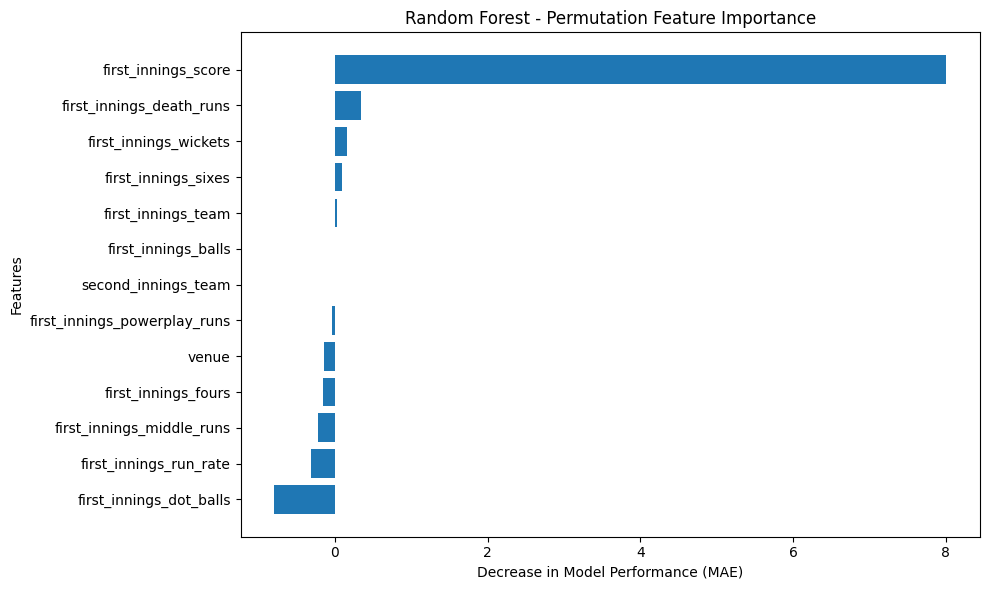

In [ ]:

# CELL 32: Random Forest Feature Importance

from sklearn.inspection import permutation_importance

# Calculate permutation importance on unseen test data
permutation_results = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

# Create importance dataframe
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": permutation_results.importances_mean,
    "Standard Deviation": permutation_results.importances_std
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance)

# Visualize feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Decrease in Model Performance (MAE)")
plt.ylabel("Features")
plt.title("Random Forest - Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:

# CELL 33: Gradient Boosting Regression

from sklearn.ensemble import GradientBoostingRegressor

# Create Gradient Boosting model
gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Train the model
gradient_boosting_model.fit(X_train, y_train)

# Make predictions
gradient_predictions = gradient_boosting_model.predict(X_test)

# Compare all models
results = pd.DataFrame([
    evaluate_model("Baseline (Mean)", y_test, dummy_predictions),
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Decision Tree", y_test, tree_predictions),
    evaluate_model("Random Forest", y_test, forest_predictions),
    evaluate_model("Gradient Boosting", y_test, gradient_predictions)
])

# Sort by MAE
results = results.sort_values(
    by="MAE"
).reset_index(drop=True)

display(results)


,Model,MAE,RMSE,R2 Score
0,Random Forest,23.46,32.63,0.115
1,Decision Tree,24.05,32.69,0.112
2,Gradient Boosting,24.41,33.28,0.080
3,Linear Regression,25.15,33.33,0.077
4,Baseline (Mean),29.65,35.64,-0.055


In [ ]:

# CELL 34: Support Vector Regression

from sklearn.svm import SVR

# Create SVR model
svr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVR(
        kernel="rbf",
        C=100,
        epsilon=5,
        gamma="scale"
    ))
])

# Train model
svr_model.fit(X_train, y_train)

# Make predictions
svr_predictions = svr_model.predict(X_test)

# Compare all models
results = pd.DataFrame([
    evaluate_model("Baseline (Mean)", y_test, dummy_predictions),
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Decision Tree", y_test, tree_predictions),
    evaluate_model("Random Forest", y_test, forest_predictions),
    evaluate_model("Gradient Boosting", y_test, gradient_predictions),
    evaluate_model("Support Vector Regression", y_test, svr_predictions)
])

results = results.sort_values(
    by="MAE"
).reset_index(drop=True)

display(results)


,Model,MAE,RMSE,R2 Score
0,Support Vector Regression,22.96,33.78,0.052
1,Random Forest,23.46,32.63,0.115
2,Decision Tree,24.05,32.69,0.112
3,Gradient Boosting,24.41,33.28,0.080
4,Linear Regression,25.15,33.33,0.077
5,Baseline (Mean),29.65,35.64,-0.055


In [ ]:

# Check player-related columns in the cleaned dataset

player_columns = [
    col for col in df_clean.columns
    if any(word in col.lower() for word in
           ["batter", "bowler", "player", "wide", "no_ball"])
]

print("Player-related columns:")
print(player_columns)



Player-related columns:
['batter', 'runs_batter', 'bowler', 'runs_bowler', 'player_out', 'review_batter', 'player_of_match', 'new_batter', 'batter_runs', 'batter_balls', 'bowler_wicket', 'next_batter']


In [ ]:

# Inspect columns needed for player batting profiles

batting_columns = [
    col for col in df_clean.columns
    if any(word in col.lower() for word in [
        "batter", "runs", "extra", "wide", "noball",
        "no_ball", "valid_ball", "over", "ball"
    ])
]

print("Relevant columns:")
print(batting_columns)

print("\nData types:")
display(df_clean[batting_columns].dtypes)

print("\nSample records:")
display(df_clean[batting_columns].head(10))


Relevant columns:
['over', 'ball', 'ball_no', 'batter', 'runs_batter', 'balls_faced', 'valid_ball', 'runs_extras', 'runs_total', 'runs_bowler', 'runs_not_boundary', 'extra_type', 'runs_target', 'review_batter', 'superover_winner', 'balls_per_over', 'overs', 'team_runs', 'team_balls', 'new_batter', 'batter_runs', 'batter_balls', 'next_batter']

Data types:


,0
over,int64
ball,int64
ball_no,float64
batter,object
runs_batter,int64
balls_faced,int64
valid_ball,int64
runs_extras,int64
runs_total,int64
runs_bowler,int64



Sample records:


,over,ball,ball_no,batter,runs_batter,balls_faced,valid_ball,runs_extras,runs_total,runs_bowler,...,review_batter,superover_winner,balls_per_over,overs,team_runs,team_balls,new_batter,batter_runs,batter_balls,next_batter
0,0,1,0.1,SR Watson,0,1,1,0,0,0,...,NaN,NaN,6,20,0,1,NaN,0,1,NaN
1,0,2,0.2,SR Watson,0,1,1,0,0,0,...,NaN,NaN,6,20,0,2,NaN,0,2,NaN
2,0,3,0.3,SR Watson,0,1,1,0,0,0,...,NaN,NaN,6,20,0,3,NaN,0,3,NaN
3,0,4,0.4,SR Watson,0,1,1,0,0,0,...,NaN,NaN,6,20,0,4,NaN,0,4,NaN
4,0,5,0.5,SR Watson,0,1,1,0,0,0,...,NaN,NaN,6,20,0,5,NaN,0,5,NaN
5,0,6,0.6,SR Watson,0,1,1,0,0,0,...,NaN,NaN,6,20,0,6,NaN,0,6,NaN
6,1,1,1.1,Sharjeel Khan,0,1,1,0,0,0,...,NaN,NaN,6,20,0,7,NaN,0,1,NaN
7,1,2,1.2,Sharjeel Khan,1,1,1,0,1,1,...,NaN,NaN,6,20,1,8,NaN,1,2,NaN
8,1,3,1.3,SR Watson,2,1,1,0,2,2,...,NaN,NaN,6,20,3,9,NaN,2,7,NaN
9,1,4,1.4,SR Watson,0,1,1,0,0,0,...,NaN,NaN,6,20,3,10,NaN,2,8,NaN


In [ ]:

# Check how balls_faced and valid_ball are distributed

print("Balls faced distribution:")
display(df_clean["balls_faced"].value_counts(dropna=False))

print("\nValid ball distribution:")
display(df_clean["valid_ball"].value_counts(dropna=False))

print("\nExtra type distribution:")
display(df_clean["extra_type"].value_counts(dropna=False))

print("\nCompare balls faced and valid balls:")
display(
    pd.crosstab(
        df_clean["balls_faced"],
        df_clean["valid_ball"],
        margins=True
    )
)


Balls faced distribution:


,count
balls_faced,
1,81167
0,2632



Valid ball distribution:


,count
valid_ball,
1,80816
0,2983



Extra type distribution:


,count
extra_type,
NaN,79227
wides,2632
legbyes,1348
noballs,332
byes,238
"byes, noballs",12
"legbyes, noballs",7
penalty,3



Compare balls faced and valid balls:


valid_ball,0,1,All
balls_faced,,,
0,2632,0,2632
1,351,80816,81167
All,2983,80816,83799


In [ ]:

# Create batting performance profiles

batting_profiles = (
    df_clean.groupby("batter")
    .agg(
        total_runs=("runs_batter", "sum"),
        total_balls=("balls_faced", "sum"),
        fours=("runs_batter", lambda x: (x == 4).sum()),
        sixes=("runs_batter", lambda x: (x == 6).sum()),
        dot_balls=("runs_batter", lambda x: (x == 0).sum())
    )
    .reset_index()
)

# Calculate performance metrics
batting_profiles["strike_rate"] = (
    batting_profiles["total_runs"] /
    batting_profiles["total_balls"].replace(0, np.nan)
) * 100

batting_profiles["boundary_percentage"] = (
    (batting_profiles["fours"] + batting_profiles["sixes"]) /
    batting_profiles["total_balls"].replace(0, np.nan)
) * 100

batting_profiles["dot_ball_percentage"] = (
    batting_profiles["dot_balls"] /
    batting_profiles["total_balls"].replace(0, np.nan)
) * 100

# Round calculated metrics
batting_profiles = batting_profiles.round(2)

# Display profiles
print("Total batters:", len(batting_profiles))
display(batting_profiles.head(10))


Total batters: 420


,batter,total_runs,total_balls,fours,sixes,dot_balls,strike_rate,boundary_percentage,dot_ball_percentage
0,A Lyth,59,36,4,4,14,163.89,22.22,38.89
1,A Zampa,1,6,0,0,5,16.67,0.00,83.33
2,AB de Villiers,218,169,19,5,49,128.99,14.20,28.99
3,AD Hales,1268,874,142,50,350,145.08,21.97,40.05
4,AD Russell,184,131,15,12,70,140.46,20.61,53.44
5,ADS Fletcher,158,138,14,8,70,114.49,15.94,50.72
6,AF Milne,16,7,2,1,2,228.57,42.86,28.57
7,AGS Gous,155,111,14,8,45,139.64,19.82,40.54
8,AJ Hosein,128,107,6,7,43,119.63,12.15,40.19
9,AJ Turner,235,139,15,12,33,169.06,19.42,23.74


In [ ]:

# Recalculate dot balls using only deliveries that count as balls faced

valid_batting_deliveries = df_clean[df_clean["balls_faced"] == 1].copy()

correct_dot_balls = (
    valid_batting_deliveries
    .groupby("batter")["runs_batter"]
    .apply(lambda x: (x == 0).sum())
)

batting_profiles["dot_balls"] = (
    batting_profiles["batter"].map(correct_dot_balls).fillna(0)
)

batting_profiles["dot_ball_percentage"] = (
    batting_profiles["dot_balls"] /
    batting_profiles["total_balls"].replace(0, np.nan)
) * 100

# Keep players who faced at least 30 balls
batting_profiles_filtered = batting_profiles[
    batting_profiles["total_balls"] >= 30
].copy()

batting_profiles_filtered = batting_profiles_filtered.round(2)

print("Total batters before filtering:", len(batting_profiles))
print("Batters after filtering:", len(batting_profiles_filtered))
print("Batters excluded:", len(batting_profiles) - len(batting_profiles_filtered))

display(
    batting_profiles_filtered
    .sort_values("total_runs", ascending=False)
    .head(10)
)


Total batters before filtering: 420
Batters after filtering: 264
Batters excluded: 156


,batter,total_runs,total_balls,fours,sixes,dot_balls,strike_rate,boundary_percentage,dot_ball_percentage
73,Babar Azam,4380,3377,479,80,1099,129.70,16.55,32.54
120,Fakhar Zaman,3370,2356,332,140,818,143.04,20.03,34.72
251,Mohammad Rizwan,2974,2323,277,75,755,128.02,15.15,32.50
304,RR Rossouw,2609,1790,260,106,608,145.75,20.45,33.97
369,Shoaib Malik,2350,1834,171,81,557,128.14,13.74,30.37
189,Kamran Akmal,1942,1420,211,87,608,136.76,20.99,42.82
366,Shan Masood,1870,1398,212,37,472,133.76,17.81,33.76
237,Mohammad Hafeez,1672,1356,152,63,530,123.30,15.86,39.09
77,C Munro,1633,1090,157,78,387,149.82,21.56,35.50
355,Shadab Khan,1586,1123,113,81,376,141.23,17.28,33.48


In [ ]:

# Recalculate dot balls using only deliveries that count as balls faced

valid_batting_deliveries = df_clean[df_clean["balls_faced"] == 1].copy()

correct_dot_balls = (
    valid_batting_deliveries
    .groupby("batter")["runs_batter"]
    .apply(lambda x: (x == 0).sum())
)

batting_profiles["dot_balls"] = (
    batting_profiles["batter"].map(correct_dot_balls).fillna(0)
)

batting_profiles["dot_ball_percentage"] = (
    batting_profiles["dot_balls"] /
    batting_profiles["total_balls"].replace(0, np.nan)
) * 100

# Keep players who faced at least 30 balls
batting_profiles_filtered = batting_profiles[
    batting_profiles["total_balls"] >= 30
].copy()

batting_profiles_filtered = batting_profiles_filtered.round(2)

print("Total batters before filtering:", len(batting_profiles))
print("Batters after filtering:", len(batting_profiles_filtered))
print("Batters excluded:", len(batting_profiles) - len(batting_profiles_filtered))

display(
    batting_profiles_filtered
    .sort_values("total_runs", ascending=False)
    .head(10)
)


Total batters before filtering: 420
Batters after filtering: 264
Batters excluded: 156


,batter,total_runs,total_balls,fours,sixes,dot_balls,strike_rate,boundary_percentage,dot_ball_percentage
73,Babar Azam,4380,3377,479,80,1099,129.70,16.55,32.54
120,Fakhar Zaman,3370,2356,332,140,818,143.04,20.03,34.72
251,Mohammad Rizwan,2974,2323,277,75,755,128.02,15.15,32.50
304,RR Rossouw,2609,1790,260,106,608,145.75,20.45,33.97
369,Shoaib Malik,2350,1834,171,81,557,128.14,13.74,30.37
189,Kamran Akmal,1942,1420,211,87,608,136.76,20.99,42.82
366,Shan Masood,1870,1398,212,37,472,133.76,17.81,33.76
237,Mohammad Hafeez,1672,1356,152,63,530,123.30,15.86,39.09
77,C Munro,1633,1090,157,78,387,149.82,21.56,35.50
355,Shadab Khan,1586,1123,113,81,376,141.23,17.28,33.48


In [ ]:

# Select batting performance features for clustering

cluster_features = [
    "strike_rate",
    "boundary_percentage",
    "dot_ball_percentage"
]

X_cluster = batting_profiles_filtered[cluster_features].copy()

print("Clustering dataset shape:", X_cluster.shape)

print("\nFeature statistics:")
display(X_cluster.describe().round(2))

print("\nMissing values:")
display(X_cluster.isnull().sum())


Clustering dataset shape: (264, 3)

Feature statistics:


,strike_rate,boundary_percentage,dot_ball_percentage
count,264.00,264.00,264.00
mean,129.32,17.11,39.76
std,27.06,5.66,8.69
min,50.00,0.00,20.86
25%,115.59,13.81,33.96
50%,131.30,17.63,37.82
75%,145.86,20.45,44.21
max,192.45,31.43,70.83



Missing values:


,0
strike_rate,0
boundary_percentage,0
dot_ball_percentage,0


In [ ]:

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Standardize clustering features
X_scaled = scaler.fit_transform(X_cluster)

# Convert back to DataFrame for easy inspection
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=cluster_features,
    index=batting_profiles_filtered.index
)

print("Standardized feature statistics:")
display(X_scaled_df.describe().round(2))

print("\nFirst 5 standardized records:")
display(X_scaled_df.head())


Standardized feature statistics:


,strike_rate,boundary_percentage,dot_ball_percentage
count,264.00,264.00,264.00
mean,0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-2.94,-3.03,-2.18
25%,-0.51,-0.58,-0.67
50%,0.07,0.09,-0.22
75%,0.61,0.59,0.51
max,2.34,2.53,3.58



First 5 standardized records:


,strike_rate,boundary_percentage,dot_ball_percentage
0,1.280004,0.904152,-0.420828
2,-0.012301,-0.515426,-1.241280
3,0.583493,0.859901,-0.310205
4,0.412420,0.619175,0.783346
5,-0.549219,-0.207437,1.096777


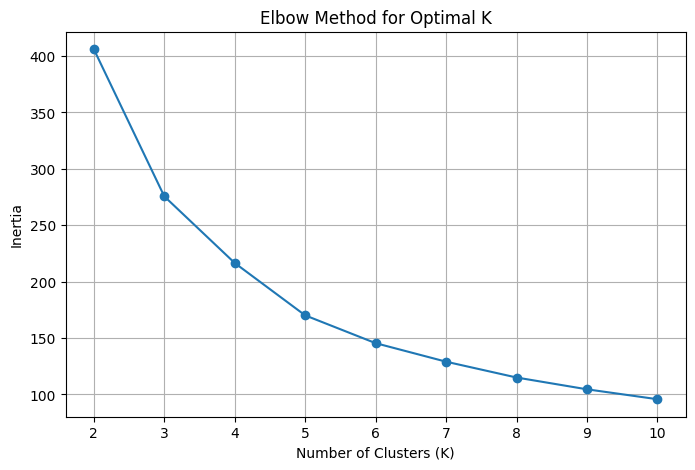

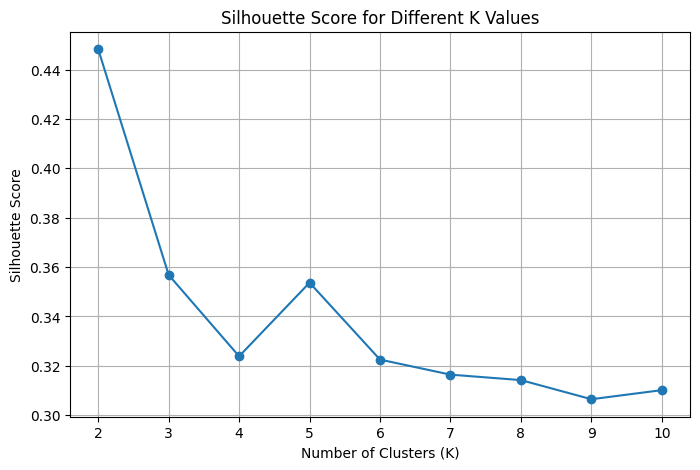

,K,Inertia,Silhouette Score
0,2,406.0026,0.4483
1,3,275.5866,0.3568
2,4,216.4960,0.3239
3,5,170.0833,0.3537
4,6,145.4466,0.3225
5,7,129.0192,0.3164
6,8,115.0050,0.3142
7,9,104.5400,0.3065
8,10,95.7617,0.3101


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia_values = []
silhouette_values = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

# Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Silhouette Score
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Display scores
cluster_scores = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(cluster_scores.round(4))


In [ ]:

# Apply K-Means with 2 clusters

final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign cluster labels
batting_profiles_filtered["cluster"] = (
    final_kmeans.fit_predict(X_scaled)
)

print("Clustering completed!")

print("\nNumber of players in each cluster:")
display(
    batting_profiles_filtered["cluster"]
    .value_counts()
    .sort_index()
)

print("\nSample clustered players:")
display(
    batting_profiles_filtered[
        ["batter", "strike_rate", "boundary_percentage",
         "dot_ball_percentage", "cluster"]
    ].head(15)
)


Clustering completed!

Number of players in each cluster:


,count
cluster,
0,186
1,78



Sample clustered players:


,batter,strike_rate,boundary_percentage,dot_ball_percentage,cluster
0,A Lyth,163.89,22.22,36.11,0
2,AB de Villiers,128.99,14.20,28.99,0
3,AD Hales,145.08,21.97,37.07,0
4,AD Russell,140.46,20.61,46.56,0
5,ADS Fletcher,114.49,15.94,49.28,1
7,AGS Gous,139.64,19.82,39.64,0
8,AJ Hosein,119.63,12.15,37.38,1
9,AJ Turner,169.06,19.42,20.86,0
11,AM Hardie,149.44,17.98,28.09,0
12,AM Rossington,150.72,26.09,37.68,0


In [ ]:

# Calculate average batting performance for each cluster

cluster_analysis = (
    batting_profiles_filtered
    .groupby("cluster")
    .agg(
        players=("batter", "count"),
        avg_runs=("total_runs", "mean"),
        avg_balls=("total_balls", "mean"),
        avg_strike_rate=("strike_rate", "mean"),
        avg_boundary_percentage=("boundary_percentage", "mean"),
        avg_dot_ball_percentage=("dot_ball_percentage", "mean")
    )
    .round(2)
)

display(cluster_analysis)


,players,avg_runs,avg_balls,avg_strike_rate,avg_boundary_percentage,avg_dot_ball_percentage
cluster,,,,,,
0,186,525.59,376.82,142.71,19.56,36.09
1,78,126.47,120.32,97.40,11.27,48.52


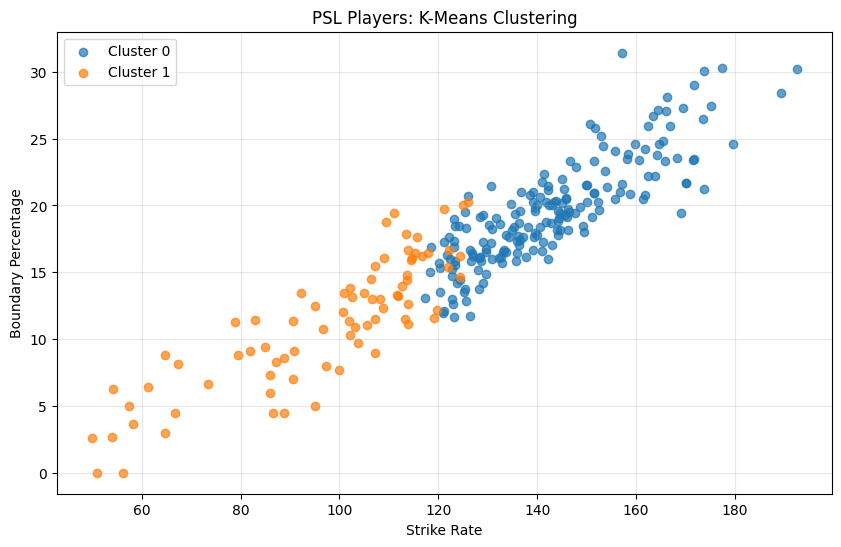

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for cluster in sorted(batting_profiles_filtered["cluster"].unique()):
    cluster_data = batting_profiles_filtered[
        batting_profiles_filtered["cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["strike_rate"],
        cluster_data["boundary_percentage"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Strike Rate")
plt.ylabel("Boundary Percentage")
plt.title("PSL Players: K-Means Clustering")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

from sklearn.decomposition import PCA

# Reduce 3 standardized features to 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=batting_profiles_filtered.index
)

# Add cluster labels
pca_df["cluster"] = batting_profiles_filtered["cluster"].values

# Display explained variance
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance retained:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

display(pca_df.head())


Explained variance ratio:
[0.7930217  0.19731762]

Total variance retained:
99.03 %


,PC1,PC2,cluster
0,1.556160,0.333723,0
2,0.315203,-1.305850,0
3,1.029599,0.303826,0
4,0.230937,1.043164,0
5,-1.022620,0.708348,1


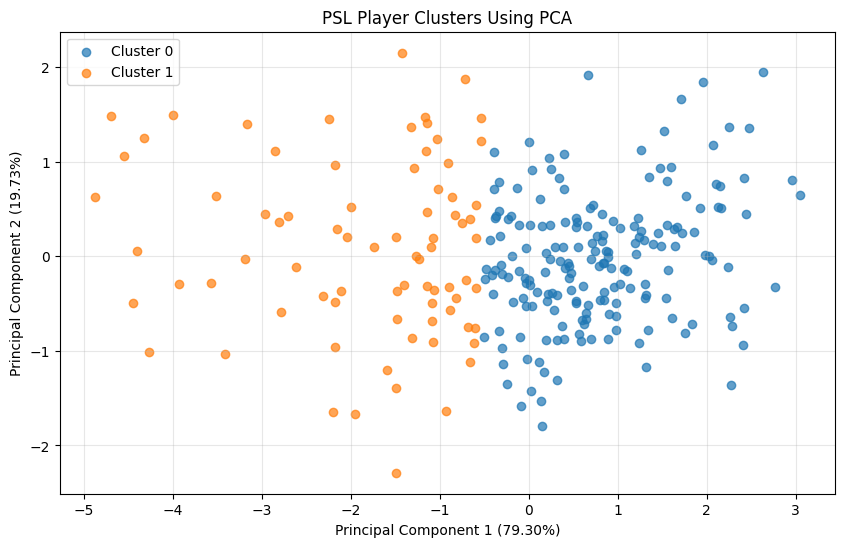

In [ ]:

plt.figure(figsize=(10, 6))

for cluster in sorted(pca_df["cluster"].unique()):
    cluster_data = pca_df[pca_df["cluster"] == cluster]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1 (79.30%)")
plt.ylabel("Principal Component 2 (19.73%)")
plt.title("PSL Player Clusters Using PCA")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


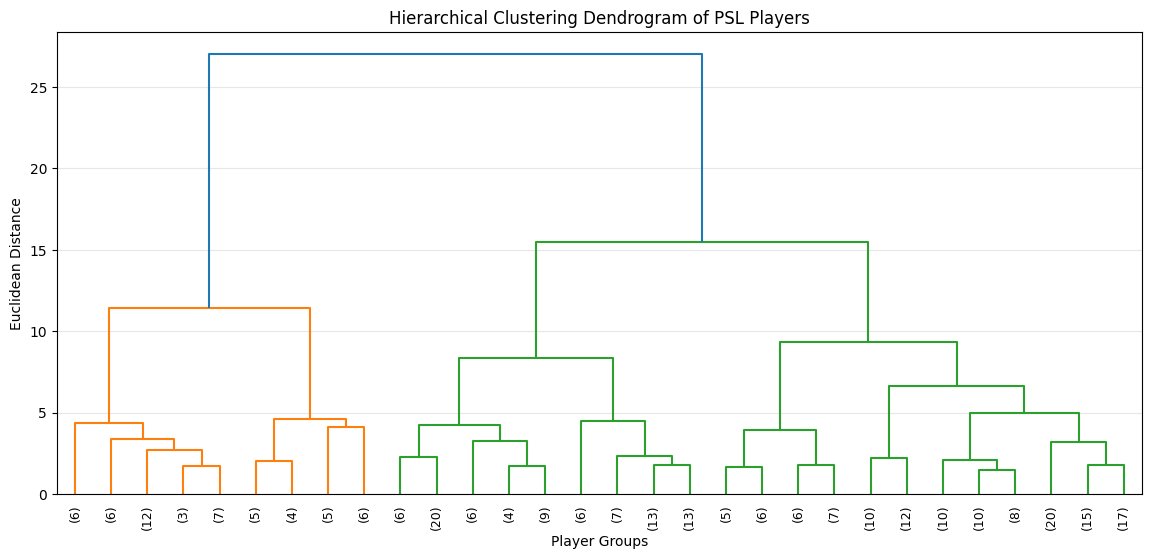

In [ ]:

from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Apply hierarchical clustering using Ward linkage
Z = linkage(X_scaled, method="ward")

# Plot dendrogram
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Hierarchical Clustering Dendrogram of PSL Players")
plt.xlabel("Player Groups")
plt.ylabel("Euclidean Distance")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [ ]:

from scipy.cluster.hierarchy import fcluster

# Create 2 clusters from hierarchical clustering
hierarchical_labels = fcluster(
    Z,
    t=2,
    criterion="maxclust"
)

# Add hierarchical cluster labels
batting_profiles_filtered["hierarchical_cluster"] = hierarchical_labels - 1

# Count players in each cluster
print("Hierarchical Cluster Distribution:")
print(
    batting_profiles_filtered["hierarchical_cluster"]
    .value_counts()
    .sort_index()
)

# Compare with K-Means
print("\nK-Means Cluster Distribution:")
print(
    batting_profiles_filtered["cluster"]
    .value_counts()
    .sort_index()
)


Hierarchical Cluster Distribution:
hierarchical_cluster
0     54
1    210
Name: count, dtype: int64

K-Means Cluster Distribution:
cluster
0    186
1     78
Name: count, dtype: int64


In [ ]:

# Compare player assignments between both algorithms
comparison = pd.crosstab(
    batting_profiles_filtered["cluster"],
    batting_profiles_filtered["hierarchical_cluster"],
    rownames=["K-Means"],
    colnames=["Hierarchical"]
)

display(comparison)


Hierarchical,0,1
K-Means,,
0,0,186
1,54,24


In [ ]:

from sklearn.metrics import adjusted_rand_score

ari_score = adjusted_rand_score(
    batting_profiles_filtered["cluster"],
    batting_profiles_filtered["hierarchical_cluster"]
)

print("Adjusted Rand Index:", round(ari_score, 4))



Adjusted Rand Index: 0.6481


In [ ]:

print("Minimum over:", df_clean["over"].min())
print("Maximum over:", df_clean["over"].max())

print("\nFirst 20 unique over values:")
print(sorted(df_clean["over"].dropna().unique())[:20])

print("\nLast 10 unique over values:")
print(sorted(df_clean["over"].dropna().unique())[-10:])


Minimum over: 0
Maximum over: 19

First 20 unique over values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]

Last 10 unique over values:
[np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]


In [ ]:

def assign_phase(over):
    if 0 <= over <= 5:
        return "Powerplay"
    elif 6 <= over <= 15:
        return "Middle"
    elif 16 <= over <= 19:
        return "Death"

df_clean["phase"] = df_clean["over"].apply(assign_phase)

# Check phase distribution
print("Delivery count by phase:")
print(df_clean["phase"].value_counts())

# Display sample records
display(df_clean[["over", "batter", "runs_batter", "balls_faced", "phase"]].head(15))


Delivery count by phase:
phase
Middle       42954
Powerplay    26619
Death        14226
Name: count, dtype: int64


,over,batter,runs_batter,balls_faced,phase
0,0,SR Watson,0,1,Powerplay
1,0,SR Watson,0,1,Powerplay
2,0,SR Watson,0,1,Powerplay
3,0,SR Watson,0,1,Powerplay
4,0,SR Watson,0,1,Powerplay
5,0,SR Watson,0,1,Powerplay
6,1,Sharjeel Khan,0,1,Powerplay
7,1,Sharjeel Khan,1,1,Powerplay
8,1,SR Watson,2,1,Powerplay
9,1,SR Watson,0,1,Powerplay


In [ ]:

phase_batting = (
    df_clean[df_clean["balls_faced"] == 1]
    .groupby(["batter", "phase"])
    .agg(
        total_runs=("runs_batter", "sum"),
        total_balls=("balls_faced", "sum"),
        fours=("runs_batter", lambda x: (x == 4).sum()),
        sixes=("runs_batter", lambda x: (x == 6).sum()),
        dot_balls=("runs_batter", lambda x: (x == 0).sum())
    )
    .reset_index()
)

phase_batting["strike_rate"] = (
    phase_batting["total_runs"] /
    phase_batting["total_balls"] * 100
)

phase_batting["boundary_percentage"] = (
    (phase_batting["fours"] + phase_batting["sixes"]) /
    phase_batting["total_balls"] * 100
)

phase_batting["dot_ball_percentage"] = (
    phase_batting["dot_balls"] /
    phase_batting["total_balls"] * 100
)

phase_batting = phase_batting.round(2)

print("Phase-wise batting dataset shape:", phase_batting.shape)
display(phase_batting.head(15))


Phase-wise batting dataset shape: (920, 10)


,batter,phase,total_runs,total_balls,fours,sixes,dot_balls,strike_rate,boundary_percentage,dot_ball_percentage
0,A Lyth,Middle,4,6,0,0,2,66.67,0.00,33.33
1,A Lyth,Powerplay,55,30,4,4,11,183.33,26.67,36.67
2,A Zampa,Death,1,2,0,0,1,50.00,0.00,50.00
3,A Zampa,Middle,0,4,0,0,4,0.00,0.00,100.00
4,AB de Villiers,Death,56,32,3,4,8,175.00,21.88,25.00
5,AB de Villiers,Middle,142,124,12,1,36,114.52,10.48,29.03
6,AB de Villiers,Powerplay,20,13,4,0,5,153.85,30.77,38.46
7,AD Hales,Death,25,13,2,2,4,192.31,30.77,30.77
8,AD Hales,Middle,501,373,37,22,114,134.32,15.82,30.56
9,AD Hales,Powerplay,742,488,103,26,206,152.05,26.43,42.21


In [ ]:

import pandas as pd
from IPython.display import display

# ==========================================
# PSL DATA MINING PROJECT - MASTER RESULTS
# ==========================================

results = [

    # DATASET AND CLEANING
    ["Dataset", "Data Loading",
     "83,799 deliveries, 64 columns, 357 matches, 12 seasons"],

    ["Data Cleaning", "Missing Values",
     "1,187,261 missing cells identified"],

    ["Data Cleaning", "Duplicate Analysis",
     "5,796 repeated delivery keys; 0 exact duplicate rows removed"],

    ["Data Cleaning", "Outlier Detection (IQR)",
     "4,572 extras outliers identified; retained for investigation"],

    ["Data Cleaning", "Data Quality",
     "Consistency checks and conservative cleaning completed"],

    # EDA
    ["EDA", "Descriptive Statistics",
     "Mean, median, standard deviation, minimum, maximum and quartiles"],

    ["EDA", "Run and Wicket Analysis",
     "Runs, wickets, dismissals and innings statistics"],

    ["EDA", "Match Phase Analysis",
     "Powerplay, middle-over and death-over analysis"],

    ["EDA", "Venue and Season Analysis",
     "Performance comparisons across venues and seasons"],

    ["EDA", "Toss Hypothesis Testing",
     "205/357 toss winners won (57.42%); p-value = 0.00584"],

    ["EDA", "Correlation Analysis",
     "Correlation matrix and heatmap generated"],

    # FEATURE ENGINEERING
    ["Feature Engineering", "Innings Dataset",
     "719 innings, 18 columns"],

    ["Feature Engineering", "Match Dataset",
     "357 matches; 354 complete matches used for regression"],

    ["Feature Engineering", "Chronological Split",
     "311 training matches; 43 testing matches (2026)"],

    # REGRESSION MODELS
    ["Regression", "Baseline Model",
     "MAE = 29.65, RMSE = 35.64, R2 = -0.055"],

    ["Regression", "Linear Regression",
     "MAE = 25.15, RMSE = 33.33, R2 = 0.077"],

    ["Regression", "Decision Tree",
     "MAE = 24.05, RMSE = 32.69, R2 = 0.112"],

    ["Regression", "Random Forest",
     "MAE = 23.46, RMSE = 32.63, R2 = 0.115"],

    ["Regression", "Gradient Boosting",
     "MAE = 24.41, RMSE = 33.28, R2 = 0.080"],

    ["Regression", "Support Vector Regression",
     "MAE = 22.96, RMSE = 33.78, R2 = 0.052"],

    ["Regression", "Model Comparison",
     "Random Forest: best RMSE and R2; SVR: best MAE"],

    ["Regression", "Prediction Error Analysis",
     "Actual vs predicted scores and five largest prediction errors examined"],

    ["Regression", "Permutation Importance",
     "First innings score was the most important feature"],

    # PLAYER PROFILING
    ["Player Analysis", "Batting Profiles",
     "420 batters identified; 264 retained after minimum 30 balls filter"],

    ["Player Analysis", "Player Features",
     "Strike rate, boundary percentage and dot-ball percentage"],

    ["Clustering", "StandardScaler",
     "Three features standardized; mean approximately 0 and standard deviation approximately 1"],

    # K-MEANS
    ["Clustering", "Elbow Method",
     "Inertia calculated for K = 2 to 10"],

    ["Clustering", "Silhouette Analysis",
     "Best silhouette score = 0.4483 at K = 2"],

    ["Clustering", "K-Means",
     "2 clusters: Cluster 0 = 186 players; Cluster 1 = 78 players"],

    ["Clustering", "Cluster 0 Profile",
     "Average SR = 142.71; Boundary = 19.56%; Dot balls = 36.09%"],

    ["Clustering", "Cluster 1 Profile",
     "Average SR = 97.40; Boundary = 11.27%; Dot balls = 48.52%"],

    ["Clustering", "Cluster Visualization",
     "Strike rate vs boundary percentage scatter plot"],

    # PCA
    ["Dimensionality Reduction", "PCA",
     "PC1 = 79.30%; PC2 = 19.73%; Total variance = 99.03%"],

    ["Dimensionality Reduction", "PCA Visualization",
     "Two-dimensional visualization of player clusters"],

    # HIERARCHICAL CLUSTERING
    ["Clustering", "Hierarchical Clustering",
     "Ward linkage; 2 clusters: Cluster 0 = 54; Cluster 1 = 210"],

    ["Clustering", "Dendrogram",
     "Hierarchical cluster merging visualized"],

    ["Clustering", "Cross-tabulation",
     "KMeans 0 / Hierarchical 1 = 186; KMeans 1 / Hierarchical 0 = 54; KMeans 1 / Hierarchical 1 = 24"],

    ["Clustering", "Adjusted Rand Index",
     "ARI = 0.6481; moderate-to-good agreement"],

    # PHASE-WISE ANALYSIS
    ["Feature Engineering", "Over Numbering",
     "Zero-based overs confirmed: 0 to 19"],

    ["Feature Engineering", "Phase Assignment",
     "Powerplay = 26,619; Middle = 42,954; Death = 14,226 deliveries"],

    ["Feature Engineering", "Phase-wise Player Profiles",
     "Currently calculating runs, balls, boundaries, strike rate and dot-ball percentage"]
]

# Create master table
master_results = pd.DataFrame(
    results,
    columns=["Category", "Technique / Model", "Results / Output"]
)

# Add numbering
master_results.insert(
    0,
    "No.",
    range(1, len(master_results) + 1)
)

# Display complete table
print("PSL DATA MINING PROJECT - COMPLETE RESULTS SUMMARY")
print("Total techniques and analyses:", len(master_results))

display(master_results)

# Export CSV
master_results.to_csv(
    "PSL_Master_Results_Table.csv",
    index=False
)

print("\nCSV file saved: PSL_Master_Results_Table.csv")


PSL DATA MINING PROJECT - COMPLETE RESULTS SUMMARY
Total techniques and analyses: 41


,No.,Category,Technique / Model,Results / Output
0,1,Dataset,Data Loading,"83,799 deliveries, 64 columns, 357 matches, 12..."
1,2,Data Cleaning,Missing Values,"1,187,261 missing cells identified"
2,3,Data Cleaning,Duplicate Analysis,"5,796 repeated delivery keys; 0 exact duplicat..."
3,4,Data Cleaning,Outlier Detection (IQR),"4,572 extras outliers identified; retained for..."
4,5,Data Cleaning,Data Quality,Consistency checks and conservative cleaning c...
5,6,EDA,Descriptive Statistics,"Mean, median, standard deviation, minimum, max..."
6,7,EDA,Run and Wicket Analysis,"Runs, wickets, dismissals and innings statistics"
7,8,EDA,Match Phase Analysis,"Powerplay, middle-over and death-over analysis"
8,9,EDA,Venue and Season Analysis,Performance comparisons across venues and seasons
9,10,EDA,Toss Hypothesis Testing,205/357 toss winners won (57.42%); p-value = 0...



CSV file saved: PSL_Master_Results_Table.csv
